# Práctica 5. Análisis semántico del corpus

En las prácticas anteriores trabajé con la forma del texto: frecuencias, categorías gramaticales y
estructura de las oraciones. Aquí paso al significado. La idea central es representar palabras,
oraciones y documentos como vectores, de modo que dos textos que signifiquen algo parecido queden
cerca aunque no compartan palabras.

Uso cuatro modelos, porque cada uno responde preguntas distintas:

| Modelo | Qué representa | Para qué lo uso |
|---|---|---|
| **Word2Vec** | Una palabra, un solo vector | Relaciones entre conceptos dentro de este corpus |
| **FastText** | Una palabra a partir de sus pedazos | Comparar con Word2Vec y manejar errores de escritura |
| **all-MiniLM-L6-v2** (Sentence Transformers) | Una oración completa | Comparar oraciones, secciones y documentos |
| **bert-base-uncased** | Una palabra dentro de su oración | Ver cómo cambia el sentido según el contexto |

Dos decisiones importantes vienen de las prácticas anteriores. Como el léxico distintivo mide tema y
no engaño, toda comparación entre ofertas falsas y legítimas se hace **dentro de una misma industria**
y con pruebas de significancia. Y como el corpus no trae fechas, las "etapas del texto" de la
actividad 4 son las **secciones del anuncio**: título, perfil de empresa, descripción, requisitos y
prestaciones. Son lo más parecido a capítulos que tiene una oferta de empleo.

**Para reproducir:** además de lo usado antes, solo hace falta `pip install gensim`. Los modelos
preentrenados se descargan solos la primera vez. La primera ejecución tarda unos 10 minutos. Después
los vectores se cargan de `corpus_procesado/embeddings/`, y si se borra esa carpeta se recalcula todo.
Word2Vec y FastText se entrenan con varios hilos, así que al reentrenarlos los números de la sección 2
y la red pueden cambiar un poco, aunque los vecinos principales se mantienen.

In [1]:
import gc, gzip, html, json, os, re, time, unicodedata, warnings
from collections import Counter
from difflib import SequenceMatcher
from itertools import combinations
from pathlib import Path

os.environ["TOKENIZERS_PARALLELISM"] = "false"
os.environ["HF_HUB_DISABLE_PROGRESS_BARS"] = "1"
warnings.filterwarnings("ignore")

import matplotlib.pyplot as plt
import networkx as nx
import numpy as np
import pandas as pd
import torch
import transformers
from gensim.models import FastText, KeyedVectors, Word2Vec
from gensim.models.phrases import ENGLISH_CONNECTOR_WORDS, Phrases
from huggingface_hub.utils import logging as hf_logging
from matplotlib.colors import LinearSegmentedColormap
from nltk.tokenize import sent_tokenize
from scipy.cluster.hierarchy import leaves_list, linkage
from scipy.sparse import coo_matrix, csr_matrix
from scipy.sparse.csgraph import connected_components
from scipy.stats import chi2, false_discovery_control, mannwhitneyu, spearmanr
from sentence_transformers import SentenceTransformer
from sklearn.cluster import KMeans, MiniBatchKMeans
from sklearn.decomposition import PCA
from sklearn.feature_extraction.text import CountVectorizer, TfidfTransformer, TfidfVectorizer
from sklearn.manifold import TSNE
from sklearn.metrics import roc_auc_score, silhouette_score
from transformers import AutoModel, AutoTokenizer

transformers.logging.set_verbosity_error()
hf_logging.set_verbosity_error()

RUTA = Path("corpus_procesado")
if not RUTA.exists():
    RUTA = Path.home() / "Downloads" / "corpus_procesado"
CSV_PATH = RUTA.parent / "DataSet.csv"
EMB = RUTA / "embeddings"       # aquí quedan los modelos y vectores de esta práctica
EMB.mkdir(exist_ok=True)
SEMILLA = 42
rng = np.random.default_rng(SEMILLA)
DISPOSITIVO = "mps" if torch.backends.mps.is_available() else "cpu"

AZUL, NARANJA, VERDE, AMARILLO = "#2a78d6", "#eb6834", "#1baf7a", "#eda100"
MAGENTA, VERDE2, VIOLETA, ROJO = "#e87ba4", "#008300", "#6250d6", "#e34948"
GRIS, REJILLA, TENUE = "#52514e", "#dcdcd8", "#c9c8c3"
SERIES = [AZUL, NARANJA, VERDE, AMARILLO, MAGENTA, VERDE2, VIOLETA, ROJO]
DIVERGENTE = LinearSegmentedColormap.from_list("div", [AZUL, "#f2f1ee", NARANJA])
SECUENCIAL = LinearSegmentedColormap.from_list("seq", ["#f2f6fc", "#9cc1ee", AZUL, "#123f7a"])
plt.rcParams.update({
    "figure.dpi": 110, "axes.titlesize": 11, "axes.labelsize": 9.5,
    "xtick.labelsize": 8.5, "ytick.labelsize": 8.5, "legend.frameon": False,
    "legend.fontsize": 8.5, "axes.edgecolor": REJILLA, "axes.labelcolor": GRIS,
    "xtick.color": GRIS, "ytick.color": GRIS,
})

def estilizar(ax, rejilla="y"):
    ax.spines["top"].set_visible(False)
    ax.spines["right"].set_visible(False)
    if rejilla:
        ax.grid(axis=rejilla, color=REJILLA, linewidth=0.8)
        ax.set_axisbelow(True)

CORTO = {"Information Technology and Services": "IT and Services"}
corto = lambda n: CORTO.get(n, n)

def unitario(M):
    return M / np.maximum(np.linalg.norm(M, axis=-1, keepdims=True), 1e-9)

def coseno(a, b):
    return float(unitario(a) @ unitario(b))

print(f"gensim y sentence-transformers listos. Dispositivo para los Transformers: {DISPOSITIVO}")

gensim y sentence-transformers listos. Dispositivo para los Transformers: mps


## 1. Construcción de representaciones semánticas

### 1.1 Preparación: recuperar las secciones

Los artefactos de las prácticas anteriores tienen cada anuncio como un solo texto, pero necesito sus
secciones. No basta con dividir el anuncio por posición (inicio, medio, final): dos de cada tres
ofertas fraudulentas no tienen perfil de empresa, así que el "inicio" de una oferta falsa no es el
mismo tipo de texto que el de una legítima. Por eso aplico la limpieza de la Práctica 1 a cada
columna del CSV original y la enlazo con los 14,265 documentos del corpus.

In [2]:
# Misma limpieza de la Práctica 1, ahora aplicada a cada sección por separado.
RE_ETIQUETA = re.compile(r"</?[a-zA-Z][^>]*>")
RE_BLOQUE = re.compile(r"</?(p|div|li|ul|ol|br|h[1-6]|tr|td|table|section)[^>]*>", re.I)
RE_ANONIMO = re.compile(r"#(?:URL|EMAIL|PHONE)_[0-9a-fA-F]+#")
RE_ESPACIOS = re.compile(r"[^\S\n]+")
RE_LINEAS = re.compile(r"\n\s*\n+")
TIPOGRAFICOS = str.maketrans({
    "‘": "'", "’": "'", "“": '"', "”": '"', "–": "-",
    "—": "-", "…": "...", " ": " ", "​": "",
})

def limpiar(texto):
    t = html.unescape(html.unescape(texto))
    t = RE_BLOQUE.sub("\n", t)
    t = RE_ETIQUETA.sub(" ", t)
    t = RE_ANONIMO.sub(" ", t)
    t = unicodedata.normalize("NFKC", t).translate(TIPOGRAFICOS)
    t = t.replace("\r\n", "\n").replace("\r", "\n")
    t = RE_LINEAS.sub("\n", RE_ESPACIOS.sub(" ", t))
    return "\n".join(linea.strip() for linea in t.split("\n")).strip()

SECCIONES = ["title", "company_profile", "description", "requirements", "benefits"]
NOMBRE_SEC = {"title": "Título", "company_profile": "Perfil de empresa", "description": "Descripción",
              "requirements": "Requisitos", "benefits": "Prestaciones"}

crudo = pd.read_csv(CSV_PATH)
crudo["texto_limpio"] = crudo[SECCIONES].apply(
    lambda f: "\n".join(str(v).strip() for v in f if pd.notna(v)), axis=1).map(limpiar)
docs = pd.read_csv(RUTA / "corpus_limpio.csv.gz", usecols=["doc_id", "title", "industry", "categoria", "texto_limpio"])
docs = docs.merge(crudo.drop_duplicates("texto_limpio")[["texto_limpio"] + SECCIONES[1:]],
                  on="texto_limpio", how="left")
print(f"Documentos enlazados con sus secciones: {docs['description'].notna().mean():.1%} de {len(docs):,}")

filas = []
for d in docs.itertuples():
    for seccion in SECCIONES:
        valor = getattr(d, seccion)
        if isinstance(valor, str):
            for bloque in limpiar(valor).split("\n"):
                if bloque.strip():
                    filas.extend((d.doc_id, seccion, o) for o in sent_tokenize(bloque.strip()))
oraciones = pd.DataFrame(filas, columns=["doc_id", "seccion", "oracion"])
total_oraciones = len(oraciones)
repetidas = oraciones["oracion"].duplicated(keep=False).mean()

# Quito restos de Word y encabezados sueltos ("Requirements:", "1.").
palabras = oraciones["oracion"].str.count(r"[A-Za-z]{2,}")
ruido = (oraciones["oracion"].str.contains(r"mso-|<!|endif|\{|\}", regex=True)
         | oraciones["oracion"].str.lower().eq("false"))
oraciones = oraciones[~ruido & ((palabras >= 3) | ((oraciones["seccion"] == "title") & (palabras >= 1)))]

docs = docs.drop(columns=["texto_limpio"] + SECCIONES[1:]).reset_index(drop=True)
docs["industria"] = docs["industry"].fillna("(sin industria)")
fraude = (docs["categoria"] == "Fraudulenta").to_numpy()
oraciones = oraciones.merge(docs[["doc_id", "categoria", "industria"]], on="doc_id").reset_index(drop=True)
oraciones["doc"] = pd.Series(docs.index, index=docs["doc_id"]).reindex(oraciones["doc_id"]).to_numpy()
unicas = pd.Index(oraciones["oracion"].unique())
oraciones["uid"] = unicas.get_indexer(oraciones["oracion"])

print(f"Oraciones totales: {total_oraciones:,}")
print(f"Oraciones que son copia de otra o tienen copia: {repetidas:.1%}")
print(f"Después de filtrar ruido: {len(oraciones):,}, de las cuales {len(unicas):,} son distintas\n")
print(oraciones.groupby(["seccion", "categoria"]).size().unstack().reindex(SECCIONES)
      .rename(index=NOMBRE_SEC).to_string())
print("\nPlantillas más repetidas:")
for oracion, n in oraciones["oracion"].value_counts().head(4).items():
    print(f"  {n:>4}x  {oracion[:95]}")

Documentos enlazados con sus secciones: 100.0% de 14,265


Oraciones totales: 471,700
Oraciones que son copia de otra o tienen copia: 57.1%
Después de filtrar ruido: 422,629, de las cuales 242,696 son distintas

categoria          Fraudulenta  Legítima
seccion                                 
Título                     682     13679
Perfil de empresa         1416     73149
Descripción               8964    164510
Requisitos                4463    115242
Prestaciones              1889     38635

Plantillas más repetidas:
   333x  We Provide Full Time Permanent Positions for many medium to large US companies.
   307x  Established on the principles that full time education is not for everyone Spectrum Learning is
   307x  We also are official re-sellers for The Institute of Recruiters / Study Course professional cou
   307x  It is our mission to help anyone wishing to pursue an apprenticeship onto the right qualificati


Todos los documentos se enlazaron. El total de oraciones es un poco mayor que en la Práctica 4
porque segmentar cada sección por separado corta algunos bloques de otra forma.

El dato que más afecta a esta práctica es que **el 57 % de las oraciones son copias de otra**. La
deduplicación de la Práctica 1 quitó anuncios idénticos, pero no los párrafos que una misma empresa
repite en todas sus ofertas. Si entreno con todo, los vectores aprenden plantillas en vez del idioma
de los anuncios. Por eso entreno y codifico **oraciones únicas**, y además quito restos de Word
(`<!--[if gte mso 9]>`) y encabezados sueltos como `Requirements:`.

### 1.2 Word2Vec y FastText

**Word2Vec** (Mikolov et al., 2013) aprende un vector por palabra con una tarea simple: dada una
palabra, predecir las que la rodean. Uso la variante skip-gram. Como dos palabras que aparecen en
contextos parecidos reciben vectores parecidos, el significado se aprende solo a partir del uso.

**FastText** (Bojanowski et al., 2017) hace lo mismo, pero construye el vector de una palabra sumando
los de sus pedazos de 3 a 6 letras. Por eso puede dar un vector a cualquier palabra, aunque nunca la
haya visto.

Entreno ambos en el corpus, con 200 dimensiones, ventana de 5 palabras y un mínimo de 10 apariciones.
Antes uno las expresiones frecuentes con `Phrases`, para que `data_entry` o `customer_service` sean
un solo término. Entrenar en el corpus tiene una ventaja clara: los vectores reflejan cómo se usa
cada palabra en anuncios de empleo y no en inglés general.

In [3]:
RE_PALABRA = re.compile(r"^[a-z][a-z0-9+#.&'-]*[a-z0-9+#]$|^[a-z]$")

def oraciones_entrenamiento():
    # Tokens de la Práctica 3, en minúsculas y sin repetir oraciones.
    vistas, salida = set(), []
    with gzip.open(RUTA / "corpus_pos.jsonl.gz", "rt", encoding="utf-8") as f:
        for linea in f:
            for oracion in json.loads(linea)["tokens"]:
                t = [w.lower() for w in oracion
                     if RE_PALABRA.match(w.lower()) and not w.lower().startswith("mso-")]
                clave = " ".join(t)
                if len(t) >= 3 and clave not in vistas:
                    vistas.add(clave)
                    salida.append(t)
    return salida

PARAMETROS = dict(vector_size=200, window=5, min_count=10, sg=1, negative=10, sample=1e-4,
                  workers=6, seed=SEMILLA)
ruta_w2v, ruta_ft = EMB / "word2vec.kv", EMB / "fasttext.kv"
if ruta_w2v.exists() and ruta_ft.exists():
    w2v, ft = KeyedVectors.load(str(ruta_w2v)), KeyedVectors.load(str(ruta_ft))
    print("Modelos cargados de disco.")
else:
    inicio = time.time()
    entrenamiento = oraciones_entrenamiento()
    frases = Phrases(entrenamiento, min_count=30, threshold=30,
                     connector_words=ENGLISH_CONNECTOR_WORDS).freeze()
    entrenamiento = [frases[o] for o in entrenamiento]
    print(f"Entrenando con {len(entrenamiento):,} oraciones únicas y "
          f"{sum(map(len, entrenamiento)):,} tokens")
    w2v = Word2Vec(entrenamiento, epochs=8, **PARAMETROS).wv
    ft = FastText(entrenamiento, epochs=5, min_n=3, max_n=6, bucket=200_000, **PARAMETROS).wv
    w2v.save(str(ruta_w2v))
    ft.save(str(ruta_ft))
    del entrenamiento
    gc.collect()
    print(f"Entrenados en {time.time() - inicio:.0f} s")
frases_vocab = [w for w in w2v.index_to_key if "_" in w]
print(f"Vocabulario: {len(w2v):,} términos, {len(frases_vocab):,} son frases "
      f"({', '.join(frases_vocab[1:6])}, ...)")

Modelos cargados de disco.
Vocabulario: 10,610 términos, 749 son frases (social_media, customer_service, communication_skills, this_position, ideal_candidate, ...)


### 1.3 Sentence Transformers

`all-MiniLM-L6-v2` es un Transformer pequeño, ajustado para que oraciones con significado parecido
tengan vectores cercanos. Da 384 dimensiones por oración. Codifico cada oración única y obtengo el
vector de un documento como el promedio de los vectores de sus oraciones. Lo hago así porque el
modelo solo lee 256 piezas de texto y un anuncio completo no le cabría.

In [4]:
ruta_sbert = EMB / "sbert_oraciones.npy"
NOMBRE_SBERT = "sentence-transformers/all-MiniLM-L6-v2"
sbert = SentenceTransformer(NOMBRE_SBERT, device="cpu")
if ruta_sbert.exists():
    E = np.load(ruta_sbert)
    print("Vectores de oraciones cargados de disco.")
else:
    inicio = time.time()
    modelo = SentenceTransformer(NOMBRE_SBERT, device=DISPOSITIVO)
    E = np.zeros((len(unicas), 384), dtype=np.float16)
    textos = unicas.tolist()
    orden = np.argsort([len(t) for t in textos])
    for i in range(0, len(textos), 20_000):
        lote = orden[i:i + 20_000]
        E[lote] = modelo.encode([textos[j] for j in lote], batch_size=64, normalize_embeddings=True,
                                show_progress_bar=False).astype(np.float16)
    np.save(ruta_sbert, E)
    del modelo
    gc.collect()
    print(f"{len(textos):,} oraciones codificadas en {(time.time() - inicio) / 60:.1f} min")
E = E.astype(np.float32)

# El vector de un documento es el promedio de los vectores de sus oraciones.
D = np.zeros((len(docs), 384), dtype=np.float32)
np.add.at(D, oraciones["doc"].to_numpy(), E[oraciones["uid"].to_numpy()])
D = unitario(D)
np.save(EMB / "sbert_documentos.npy", D.astype(np.float16))
print(f"Matriz de oraciones {E.shape}, matriz de documentos {D.shape}")

Vectores de oraciones cargados de disco.


Matriz de oraciones (242696, 384), matriz de documentos (14265, 384)


### 1.4 BERT: vectores contextuales

Word2Vec le da un solo vector a `application`, sea una aplicación móvil o una solicitud de empleo.
**BERT** (Devlin et al., 2019) lee la oración completa y le da a cada aparición un vector distinto.

Como no hace falta hacerlo con todo el vocabulario, elegí 12 palabras frecuentes con varios sentidos
posibles. De cada una tomo hasta 800 oraciones fraudulentas y 2,200 legítimas, y guardo el vector de
la palabra como el promedio de las últimas 4 capas del modelo (768 dimensiones).

In [5]:
PALABRAS = ["development", "application", "experience", "position", "home", "service",
            "training", "support", "work", "company", "pay", "opportunity"]
ruta_bert = EMB / "bert_contextual.npz"
ruta_bert_meta = EMB / "bert_contextual.parquet"
NOMBRE_BERT = "bert-base-uncased"

def extraer_contextuales():
    tok = AutoTokenizer.from_pretrained(NOMBRE_BERT)
    modelo = AutoModel.from_pretrained(NOMBRE_BERT).to(DISPOSITIVO).eval()
    minusculas = oraciones["oracion"].str.lower()
    metas, vectores = [], {}
    for palabra in PALABRAS:
        contiene = minusculas.str.contains(rf"\b{palabra}\b", regex=True)
        q = oraciones[contiene].drop_duplicates(["uid", "seccion", "categoria"])
        f, l = q[q["categoria"] == "Fraudulenta"], q[q["categoria"] == "Legítima"]
        q = pd.concat([f.sample(min(len(f), 800), random_state=1),
                       l.sample(min(len(l), 2200), random_state=1)]).reset_index(drop=True)
        id_palabra = tok.convert_tokens_to_ids(palabra)
        V = np.full((len(q), 768), np.nan, dtype=np.float32)
        textos = q["oracion"].tolist()
        orden = np.argsort([len(t) for t in textos])
        for i in range(0, len(textos), 32):
            lote = orden[i:i + 32]
            e = tok([textos[j] for j in lote], return_tensors="pt", padding=True, truncation=True,
                    max_length=128).to(DISPOSITIVO)
            with torch.no_grad():
                capas = modelo(**e, output_hidden_states=True).hidden_states
            H = torch.stack(capas[-4:]).mean(0).cpu().numpy()      # promedio de las últimas 4 capas
            ids = e["input_ids"].cpu().numpy()
            for r, j in enumerate(lote):
                pos = np.where(ids[r] == id_palabra)[0]
                if len(pos):
                    V[j] = H[r, pos[0]]
        validos = ~np.isnan(V[:, 0])
        metas.append(q[validos].assign(palabra=palabra))
        vectores[palabra] = V[validos].astype(np.float16)
    del modelo
    gc.collect()
    meta = pd.concat(metas, ignore_index=True)[["palabra", "doc", "uid", "seccion", "categoria", "industria", "oracion"]]
    meta.to_parquet(ruta_bert_meta)
    np.savez_compressed(ruta_bert, **vectores)

if not (ruta_bert.exists() and ruta_bert_meta.exists()):
    inicio = time.time()
    extraer_contextuales()
    print(f"Vectores contextuales extraídos en {(time.time() - inicio) / 60:.1f} min")
bert_meta = pd.read_parquet(ruta_bert_meta)
bert_datos = np.load(ruta_bert)
BERT = {p: (bert_meta[bert_meta["palabra"] == p].reset_index(drop=True), bert_datos[p].astype(np.float32))
        for p in PALABRAS}
print(f"{len(bert_meta):,} apariciones de {len(PALABRAS)} palabras")

27,742 apariciones de 12 palabras


In [6]:
resumen = pd.DataFrame([
    ["Word2Vec skip-gram", "Entrenado en el corpus", "Palabra o frase", 200, f"{len(w2v):,} términos"],
    ["FastText skip-gram", "Entrenado en el corpus", "Palabra y sus pedazos", 200, "Cualquier palabra"],
    ["all-MiniLM-L6-v2", "Preentrenado", "Oración y documento", E.shape[1], f"{E.shape[0]:,} oraciones"],
    ["bert-base-uncased", "Preentrenado", "Palabra en contexto", 768, f"{len(bert_meta):,} apariciones"],
], columns=["Modelo", "Origen", "Representa", "Dimensión", "Cobertura"]).set_index("Modelo")
print(resumen.to_string())

print("\nEjemplos de representaciones (primeras 6 dimensiones):")
fmt = lambda v: "[" + ", ".join(f"{x:+.2f}" for x in v[:6]) + ", ...]"
print(f"  Word2Vec  'salary'           {fmt(w2v['salary'])}  norma {np.linalg.norm(w2v['salary']):.2f}")
print(f"  Word2Vec  'data_entry'       {fmt(w2v['data_entry'])}  norma {np.linalg.norm(w2v['data_entry']):.2f}")
print(f"  FastText  'salary'           {fmt(ft['salary'])}  norma {np.linalg.norm(ft['salary']):.2f}")
ejemplo = "We offer competitive salaries and excellent benefits."
v = sbert.encode(ejemplo, normalize_embeddings=True)
print(f"  MiniLM    '{ejemplo[:27]}...' {fmt(v)}  norma {np.linalg.norm(v):.2f}")
q, V = BERT["application"]
print(f"  BERT      'application' (1)  {fmt(V[0])}  en: {q['oracion'][0][:60]}")
print(f"  BERT      'application' (2)  {fmt(V[1])}  en: {q['oracion'][1][:60]}")
print(f"  coseno entre esas dos apariciones: {coseno(V[0], V[1]):.2f}")

                                    Origen             Representa  Dimensión           Cobertura
Modelo                                                                                          
Word2Vec skip-gram  Entrenado en el corpus        Palabra o frase        200     10,610 términos
FastText skip-gram  Entrenado en el corpus  Palabra y sus pedazos        200   Cualquier palabra
all-MiniLM-L6-v2              Preentrenado    Oración y documento        384   242,696 oraciones
bert-base-uncased             Preentrenado    Palabra en contexto        768  27,742 apariciones

Ejemplos de representaciones (primeras 6 dimensiones):
  Word2Vec  'salary'           [-0.00, +0.13, +0.62, +0.87, -0.14, +0.94, ...]  norma 4.91
  Word2Vec  'data_entry'       [+0.27, +0.24, -0.29, +0.15, -0.56, +0.37, ...]  norma 3.95
  FastText  'salary'           [-0.00, +0.01, +0.21, -0.17, -0.06, +0.36, ...]  norma 4.80
  MiniLM    'We offer competitive salari...' [-0.02, -0.01, +0.04, +0.03, -0.05, +0.06, .

Cada vector es una lista de números que por sí sola no significa nada: una dimensión no equivale a
"salario" o "tecnología". Lo que importa es la posición de un vector respecto a los demás. El último
ejemplo muestra la diferencia con los modelos anteriores: es la misma palabra, `application`, pero
BERT le da vectores distintos en cada oración (coseno 0.64 y no 1).

## 2. Análisis de similitud semántica

Mido la similitud con el **coseno** del ángulo entre dos vectores. Vale 1 si apuntan en la misma
dirección y 0 si no tienen relación. Lo prefiero a la distancia euclidiana porque no depende del
tamaño del vector, que en Word2Vec cambia con la frecuencia de la palabra.

### 2.1 ¿Qué palabras tienen significados cercanos?

In [7]:
palabras_ej = ["salary", "visa", "remote", "data_entry", "php", "nurse", "bonus", "urgent", "home"]
tabla = pd.DataFrame({
    "Word2Vec": {p: ", ".join(f"{w} ({s:.2f})" for w, s in w2v.most_similar(p, topn=4)) for p in palabras_ej},
    "FastText": {p: ", ".join(f"{w} ({s:.2f})" for w, s in ft.most_similar(p, topn=4)) for p in palabras_ej},
})
for p, fila in tabla.iterrows():
    print(f"{p:<11} W2V: {fila['Word2Vec']}")
    print(f"{'':<11} FT : {fila['FastText']}\n")

print("Palabras mal escritas:")
for p in ["sallary", "managment", "developper", "enginer"]:
    print(f"  {p:<12} en Word2Vec: {str(p in w2v):<6} FastText: "
          + ", ".join(w for w, _ in ft.most_similar(p, topn=4)))

salary      W2V: hourly_rate (0.73), negotiable (0.72), remuneration (0.71), wage (0.71)
            FT : base_salary (0.91), salaried (0.83), uncapped_commission (0.81), competitive_salary (0.80)

visa        W2V: h1b (0.76), green_card (0.76), h1 (0.75), residency (0.73)
            FT : visas (0.94), visahq (0.90), h1b (0.82), citizens (0.80)

remote      W2V: remotely (0.59), virtual (0.57), on-site (0.57), onsite (0.52)
            FT : remotely (0.82), onsite (0.71), on-site (0.69), virtual (0.69)

data_entry  W2V: clerical (0.74), clerk (0.70), inputting (0.67), accounts_payable (0.66)
            FT : clerical (0.78), entry (0.75), clerk (0.73), incoming_and_outgoing (0.70)

php         W2V: ruby_on_rails (0.80), javascript (0.78), ruby (0.78), django (0.78)
            FT : php5 (0.93), ruby (0.88), javascript (0.88), php_mysql (0.88)

nurse       W2V: registered_nurse (0.80), practitioner (0.77), rn (0.77), lpn (0.77)
            FT : nursery (0.92), registered_nurse (0.90), 

Word2Vec encuentra relaciones de uso que dependen del corpus. `visa` está junto a `h1b` y `green_card`
porque en estos anuncios se habla del permiso de trabajo en Estados Unidos, no de la tarjeta de
crédito. `php` queda con otros lenguajes y `nurse` con sus títulos (`rn`, `lpn`). Las frases también
funcionan: `data_entry` queda con `clerical` y `clerk`.

FastText prefiere las palabras que se escriben parecido. Eso ayuda con las variantes (`visas`,
`php5`), pero también produce falsos amigos: `nursery` para `nurse` y `argenta` para `urgent`, un
nombre sin relación. Su ventaja real está al final de la salida: Word2Vec no conoce `managment` ni
`developper`, y FastText sí llega a la palabra correcta, aunque con errores como `ancillary` para
`sallary`.

`home` es el caso débil de Word2Vec. Sus vecinos (`keepers`, `mcbride`, `remodeling`) son una mezcla
sin sentido claro, y es lo esperable: el modelo está obligado a promediar todos los usos de la
palabra en un solo vector. Ese problema es justo el que resuelve BERT en la sección 4.

### 2.2 ¿Se parecen la similitud léxica y la semántica?

Empiezo por palabras, comparando cuánto se parecen sus letras con el coseno de cada modelo.

In [8]:
def parecido_letras(a, b):
    return SequenceMatcher(None, a, b).ratio()

pares = [("salary", "wage"), ("cv", "resume"), ("remote", "telecommute"), ("experience", "expertise"),
         ("bonus", "commission"), ("salary", "salaried"), ("manager", "management"), ("home", "homeless"),
         ("oil", "soil"), ("employer", "employee"), ("senior", "junior"), ("full-time", "part-time")]
tabla_pares = pd.DataFrame([(f"{a} / {b}", parecido_letras(a, b), w2v.similarity(a, b), ft.similarity(a, b))
                            for a, b in pares], columns=["Par", "Letras", "Word2Vec", "FastText"])
print(tabla_pares.set_index("Par").round(2).to_string())

frecuentes = [w for w in w2v.index_to_key[:3000] if "_" not in w]
ia, ib = rng.integers(0, len(frecuentes), (2, 20_000))
letras = np.array([parecido_letras(frecuentes[a], frecuentes[b]) for a, b in zip(ia, ib)])
c_w2v = np.array([w2v.similarity(frecuentes[a], frecuentes[b]) for a, b in zip(ia, ib)])
c_ft = np.array([ft.similarity(frecuentes[a], frecuentes[b]) for a, b in zip(ia, ib)])
print(f"\nCorrelación de Spearman con el parecido en letras (20,000 pares al azar):")
print(f"  Word2Vec {spearmanr(letras, c_w2v)[0]:.2f}    FastText {spearmanr(letras, c_ft)[0]:.2f}")

                        Letras  Word2Vec  FastText
Par                                               
salary / wage             0.20      0.71      0.76
cv / resume               0.00      0.75      0.84
remote / telecommute      0.24      0.51      0.53
experience / expertise    0.74      0.47      0.67
bonus / commission        0.27      0.55      0.65
salary / salaried         0.71      0.57      0.83
manager / management      0.71      0.49      0.67
home / homeless           0.67      0.30      0.71
oil / soil                0.86      0.61      0.83
employer / employee       0.88      0.37      0.87
senior / junior           0.67      0.63      0.83
full-time / part-time     0.56      0.72      0.88



Correlación de Spearman con el parecido en letras (20,000 pares al azar):
  Word2Vec 0.03    FastText 0.08


Hay ejemplos claros en las dos direcciones. `cv` y `resume` no comparten letras y tienen coseno 0.75
en Word2Vec. `employer` y `employee` son casi iguales en letras y solo 0.37 en Word2Vec, porque
aparecen en contextos distintos. FastText las sube a 0.87 por sus pedazos comunes, y lo mismo hace con
`home`/`homeless` (0.71 contra 0.30). En 20,000 pares al azar la correlación con el parecido en letras
es casi nula en los dos modelos, porque la mayoría de las palabras no se parecen en nada: el efecto de
FastText se nota sobre todo en las palabras que sí comparten una raíz.

Hay una limitación importante: **similar no quiere decir sinónimo**. `senior`/`junior` (0.63) y
`full-time`/`part-time` (0.72) son opuestos con coseno alto, porque los opuestos aparecen en los
mismos contextos. Estos modelos miden que dos palabras hablan de lo mismo, no que signifiquen lo mismo.

Ahora hago la comparación con oraciones. Tomo 30,000 oraciones al azar, busco la más cercana a cada
una con MiniLM y mido cuántas palabras de contenido comparten (Jaccard).

In [9]:
RE_CONTENIDO = re.compile(r"[a-z]{3,}")
VACIAS = set("the and for with our your you are will that this have has all can from not who but its their "
             "they was were been has had any out new more most into per also such other".split())
contenido = lambda s: set(RE_CONTENIDO.findall(s.lower())) - VACIAS
jaccard = lambda a, b: len(a & b) / max(1, len(a | b))

largo = np.array([len(t.split()) for t in unicas])
muestra = rng.choice(np.where((largo >= 6) & (largo <= 18))[0], 30_000, replace=False)
Em, textos_m = E[muestra], [unicas[i] for i in muestra]
sets_m = [contenido(t) for t in textos_m]

filas = []
for i in range(0, len(muestra), 3000):
    S = Em[i:i + 3000] @ Em.T
    S[np.arange(S.shape[0]), np.arange(i, i + S.shape[0])] = -1
    vecino = S.argmax(1)
    for r, j in enumerate(vecino):
        filas.append((i + r, j, S[r, j], jaccard(sets_m[i + r], sets_m[j])))
vec = pd.DataFrame(filas, columns=["a", "b", "semantica", "lexica"])
parecidas = vec[(vec["lexica"] == 0) & (vec["semantica"] > 0.7)].sort_values("semantica", ascending=False)
print(f"Vecino más cercano de {len(vec):,} oraciones: coseno medio {vec['semantica'].mean():.2f}, "
      f"Jaccard medio {vec['lexica'].mean():.2f}")
print(f"Pares con coseno > 0.7 y ninguna palabra de contenido en común: {len(parecidas):,}\n")
print("Mismo significado, palabras distintas:")
vistos = set()
for f in parecidas.itertuples():
    clave = frozenset((f.a, f.b))
    if clave not in vistos and len(vistos) < 6:
        vistos.add(clave)
        print(f"  {f.semantica:.2f}  {textos_m[f.a][:70]}\n        {textos_m[f.b][:70]}")

tfidf_m = TfidfVectorizer(stop_words="english", min_df=2).fit_transform(textos_m[:8000])
L = (tfidf_m @ tfidf_m.T).tocoo()
k = (L.row < L.col) & (L.data > 0.5)
cand = pd.DataFrame({"a": L.row[k], "b": L.col[k], "lexica": L.data[k]})
cand["semantica"] = (Em[cand["a"]] * Em[cand["b"]]).sum(1)
cand["jaccard"] = [jaccard(sets_m[a], sets_m[b]) for a, b in zip(cand["a"], cand["b"])]
print("\nPalabras parecidas, significado distinto:")
vistos = set()
for f in cand[cand["jaccard"] >= 0.25].sort_values("semantica").itertuples():
    clave = textos_m[f.a][:15]
    if clave not in vistos and len(vistos) < 4:
        vistos.add(clave)
        print(f"  coseno {f.semantica:.2f}, TF-IDF {f.lexica:.2f}  {textos_m[f.a][:70]}\n"
              f"{'':<25}{textos_m[f.b][:70]}")

Vecino más cercano de 30,000 oraciones: coseno medio 0.70, Jaccard medio 0.23
Pares con coseno > 0.7 y ninguna palabra de contenido en común: 257

Mismo significado, palabras distintas:
  0.87  Develop and maintain relationships with potential clients
        Able to identify opportunities to grow the relationship with the clien
  0.85  Thursday - 8:30 am to 5:30 pm
        • Wednesday -- 8:30 am to 5:30 pm
  0.85  BS or MS in CS or Engineering desirable
        BS or MS in Computer Science or related technical field or equivalent 
  0.84  Preparing proposals and responding to RFPs
        Assisting with RFP responses and proposal writing
  0.83  Application closing date: 3 July 2014
        Applications will close by 31 August 2014.
  0.83  Elements of these roles may include:
        The role will encompass the following:

Palabras parecidas, significado distinto:
  coseno 0.08, TF-IDF 0.81  1+ years of retouching experience is a plus
                         Experience with Veritas 

La primera lista muestra lo que un conteo de palabras no ve. `BS or MS in CS or Engineering` y
`BS or MS in Computer Science` dicen lo mismo, igual que `closing date` y `will close by`. Algunos
pares comparten raíz sin compartir la palabra exacta (`proposals`/`proposal`), porque el Jaccard no
usa lemas. La segunda lista muestra el caso contrario: `1+ years of retouching experience is a plus`
y `Experience with Veritas Backupexec a plus` tienen TF-IDF de 0.81 por compartir el molde de la
frase, pero uno pide retoque fotográfico y el otro respaldos de servidores, y su coseno es 0.08.

### 2.3 Similitud entre documentos y campañas

Antes de comparar anuncios tengo que resolver un problema. Muchas ofertas fraudulentas son variantes
de una misma plantilla con pequeños cambios. Si las cuento como independientes, cualquier prueba
estadística sale artificialmente significativa. Para encontrar esos grupos busco un umbral de coseno
y lo valido con el solapamiento real de palabras.

In [10]:
# Vecinos más cercanos de cada documento y pares casi idénticos.
K_VEC = 50
vecinos = np.zeros((len(D), K_VEC), dtype=np.int32)
cos_vecinos = np.zeros((len(D), K_VEC), dtype=np.float32)
pares_a, pares_b = [], []
UMBRAL = 0.95
for i in range(0, len(D), 1000):
    S = D[i:i + 1000] @ D.T
    S[np.arange(S.shape[0]), np.arange(i, i + S.shape[0])] = -1
    idx = np.argpartition(-S, K_VEC, axis=1)[:, :K_VEC]
    val = np.take_along_axis(S, idx, 1)
    orden = np.argsort(-val, axis=1)
    vecinos[i:i + 1000] = np.take_along_axis(idx, orden, 1)
    cos_vecinos[i:i + 1000] = np.take_along_axis(val, orden, 1)
    a, b = np.where(S >= UMBRAL)
    pares_a.extend(a + i)
    pares_b.extend(b)

texto_doc = oraciones.groupby("doc")["oracion"].apply(" ".join).reindex(range(len(docs))).fillna("")
sets_doc = [set(RE_CONTENIDO.findall(t.lower())) for t in texto_doc]
filas = []
for lo, hi in [(0.80, 0.85), (0.85, 0.90), (0.90, 0.93), (0.93, 0.95), (0.95, 0.97), (0.97, 0.99), (0.99, 1.01)]:
    m = np.where((cos_vecinos[:, 0] >= lo) & (cos_vecinos[:, 0] < hi))[0]
    s = rng.choice(m, min(400, len(m)), replace=False)
    filas.append((f"{lo:.2f} a {min(hi, 1):.2f}", len(m),
                  np.median([jaccard(sets_doc[i], sets_doc[vecinos[i, 0]]) for i in s])))
print(pd.DataFrame(filas, columns=["Coseno con su vecino", "Documentos", "Jaccard mediano"])
      .set_index("Coseno con su vecino").round(2).to_string())

_, campana = connected_components(coo_matrix((np.ones(len(pares_a)), (pares_a, pares_b)),
                                             shape=(len(D), len(D))), directed=False)
docs["campana"] = campana
docs["tam_campana"] = docs.groupby("campana")["doc_id"].transform("size")
representantes = docs.groupby("campana").head(1).index.to_numpy()      # una oferta por grupo
fr_rep = fraude[representantes]
print(f"\nCon umbral {UMBRAL}: {len(representantes):,} grupos para {len(docs):,} documentos")
print(f"Las {fraude.sum()} ofertas fraudulentas se reducen a {fr_rep.sum()} grupos independientes\n")
print(docs[fraude].groupby("campana").agg(ofertas=("title", "size"), ejemplo=("title", "first"))
      .sort_values("ofertas", ascending=False).head(6).to_string(index=False))

                      Documentos  Jaccard mediano
Coseno con su vecino                             
0.80 a 0.85                 1299             0.14
0.85 a 0.90                 3171             0.17
0.90 a 0.93                 2186             0.40
0.93 a 0.95                 1293             0.54
0.95 a 0.97                 1337             0.66
0.97 a 0.99                 1836             0.83
0.99 a 1.00                 2311             0.98

Con umbral 0.95: 10,300 grupos para 14,265 documentos
Las 680 ofertas fraudulentas se reducen a 501 grupos independientes

 ofertas                                     ejemplo
      20                 Admin Clerk Remote Position
      18 Weekly CASH Jobs, Hiring Part Time Workers.
       9                        Medical Surgical RN 
       7                   Project Manager: Engineer
       7          Senior Engineering Product Manager
       6                  Earn a nice part time PAY!


El Jaccard salta entre 0.90 y 0.95: por debajo de 0.90 los documentos más cercanos comparten menos de
una quinta parte de sus palabras, y arriba de 0.95 comparten dos tercios o más. Uso 0.95 y uno los
pares en grupos. Las 680 ofertas fraudulentas se reducen a 501 grupos independientes. A esos grupos
les llamo "campañas" en lo que sigue, aunque también hay legítimas agrupadas, como las empresas que
publican la misma oferta en varias ciudades. Desde aquí, toda prueba usa **una oferta por grupo**.

Los títulos confirman que el método encuentra algo real: `Admin Clerk Remote Position` se repite 20
veces con texto casi igual, y `Weekly CASH Jobs` 18. Son justo las campañas que la deduplicación
exacta no podía detectar.

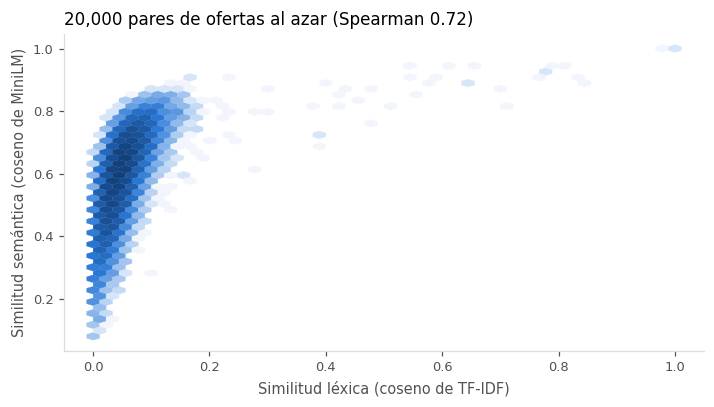

Cuantiles 10, 50 y 90.  Léxica: [0.017 0.045 0.085]   Semántica: [0.415 0.604 0.742]



Ofertas cercanas en significado con poco vocabulario en común:
                                         a                                              b    s    l
Finance/Accountancy Recruitment Consultant                         UST Testing Technician 0.80 0.01
                 Live-in caregivers needed                                     Care Giver 0.80 0.03
                           Wealth Managers                        Client Success Manager  0.81 0.03
                        Service Technician                          Applications Engineer 0.81 0.03
                       Security Consultant 1st level support engineers (MS Dynamics NAV)  0.81 0.03
                 I want to work @involvio!                  Junior Web/Software Developer 0.81 0.04


In [11]:
tfidf_docs = TfidfVectorizer(stop_words="english", min_df=3, sublinear_tf=True).fit_transform(texto_doc)
a, b = rng.integers(0, len(docs), (2, 20_000))
semantica = (D[a] * D[b]).sum(1)
lexica = np.asarray(tfidf_docs[a].multiply(tfidf_docs[b]).sum(1)).ravel()
rho = spearmanr(semantica, lexica)[0]

fig, ax = plt.subplots(figsize=(6.6, 3.8))
ax.hexbin(lexica, semantica, gridsize=45, cmap=SECUENCIAL, bins="log", mincnt=1, linewidths=0.2)
ax.set_xlabel("Similitud léxica (coseno de TF-IDF)")
ax.set_ylabel("Similitud semántica (coseno de MiniLM)")
ax.set_title(f"20,000 pares de ofertas al azar (Spearman {rho:.2f})", loc="left")
estilizar(ax, None)
fig.tight_layout()
plt.show()
print(f"Cuantiles 10, 50 y 90.  Léxica: {np.round(np.quantile(lexica, [.1, .5, .9]), 3)}   "
      f"Semántica: {np.round(np.quantile(semantica, [.1, .5, .9]), 3)}")

I, J = np.repeat(np.arange(len(D)), 5), vecinos[:, :5].ravel()
cerca = pd.DataFrame({"i": I, "j": J, "s": cos_vecinos[:, :5].ravel(),
                      "l": np.asarray(tfidf_docs[I].multiply(tfidf_docs[J]).sum(1)).ravel()})
cerca = cerca[(cerca["i"] < cerca["j"]) & (cerca["s"] > 0.8) & (cerca["l"] < 0.06)].sort_values("l")
cerca["a"], cerca["b"] = docs["title"].to_numpy()[cerca["i"]], docs["title"].to_numpy()[cerca["j"]]
print("\nOfertas cercanas en significado con poco vocabulario en común:")
print(cerca[["a", "b", "s", "l"]].head(6).round(2).to_string(index=False))

Cada celda de la gráfica cuenta pares de anuncios, y más oscuro significa más pares. La similitud
léxica y la semántica están relacionadas (Spearman 0.72), pero no son lo mismo. La mayoría de los
pares se apila en la izquierda: comparten poco vocabulario (TF-IDF cerca de 0.05) y aun así su coseno
semántico va de 0.4 a 0.75. Solo las copias aparecen en la esquina superior derecha.

Esto también advierte sobre cómo leer el coseno de MiniLM: dos anuncios al azar tienen una mediana de
0.60, porque todos son del mismo género. Un coseno de 0.8 entre documentos no es tan alto como suena.
La lista final lo confirma. `Live-in caregivers needed` y `Care Giver` son un acierto real, pero
`Finance/Accountancy Recruitment Consultant` y `UST Testing Technician` no se parecen mucho. Promediar
todas las oraciones de un anuncio capta el tono general de la oferta y borra detalles. Por eso para
las preguntas finas uso oraciones o BERT, y no el vector del documento completo.

## 3. Relaciones entre personajes y conceptos

Un corpus de ofertas de empleo no tiene personajes como una novela, pero sí tiene actores que
reaparecen: el candidato, el empleado, el cliente y los puestos. Analizo cuatro cosas: los conceptos
principales, los roles y lugares, las industrias, y los temas que distinguen al fraude.

### 3.1 Red semántica de conceptos

Tomo los 150 sustantivos más frecuentes, según las etiquetas de la Práctica 3. Uno dos conceptos solo
si cada uno está entre los 6 vecinos más cercanos del otro, para evitar que las palabras muy generales
se conecten con todo. Después busco comunidades con el algoritmo de Louvain.

In [12]:
conteo_nombres = Counter()
with gzip.open(RUTA / "corpus_pos.jsonl.gz", "rt", encoding="utf-8") as f:
    for linea in f:
        d = json.loads(linea)
        for palabras_o, etiquetas in zip(d["tokens"], d["pos"]):
            conteo_nombres.update(p.lower() for p, e in zip(palabras_o, etiquetas) if e in ("NN", "NNS"))
conceptos = [w for w, _ in conteo_nombres.most_common(400) if w in w2v and len(w) > 2][:150]

V = unitario(np.array([w2v[w] for w in conceptos]))
S = V @ V.T
np.fill_diagonal(S, -1)
K_RED = 6
top = np.argsort(-S, axis=1)[:, :K_RED]
red = nx.Graph()
red.add_nodes_from(conceptos)
for i in range(len(conceptos)):
    for j in top[i]:
        if i in top[j]:                       # solo si la cercanía es mutua
            red.add_edge(conceptos[i], conceptos[j], weight=float(S[i, j]))
red.remove_nodes_from(list(nx.isolates(red)))

comunidades = sorted(nx.community.louvain_communities(red, weight="weight", seed=SEMILLA),
                     key=len, reverse=True)
modularidad = nx.community.modularity(red, comunidades, weight="weight")
print(f"{red.number_of_nodes()} conceptos, {red.number_of_edges()} enlaces, "
      f"{len(comunidades)} comunidades, modularidad {modularidad:.2f}\n")
for i, c in enumerate(comunidades):
    orden = sorted(c, key=lambda w: -red.degree(w, weight="weight"))
    print(f"{i + 1:>2} ({len(c):>2}) {', '.join(orden[:12])}")
print("\nConceptos puente (mayor intermediación):")
intermedia = nx.betweenness_centrality(red, seed=SEMILLA)
print("  " + ", ".join(f"{w} ({v:.2f})" for w, v in sorted(intermedia.items(), key=lambda x: -x[1])[:8]))

144 conceptos, 276 enlaces, 10 comunidades, modularidad 0.69

 1 (19) employees, team, teams, developers, benefits, people, members, person, staff, candidate, individuals, someone
 2 (17) systems, software, system, technology, technologies, solutions, data, applications, analysis, web, tools, reports
 3 (17) company, industry, companies, brands, leadership, world, organization, management, brand, startup, businesses, business
 4 (16) processes, practices, design, engineering, procedures, development, implementation, support, operations, equipment, services, standards
 5 (16) position, qualifications, role, education, hours, salary, health, time, job, day, degree, training
 6 (15) marketing, strategy, plans, campaigns, plan, content, media, program, programs, research, vision, online
 7 (15) opportunity, goals, needs, success, growth, opportunities, quality, performance, results, problems, requirements, career
 8 (11) knowledge, experience, skills, year, expertise, years, plus, understa

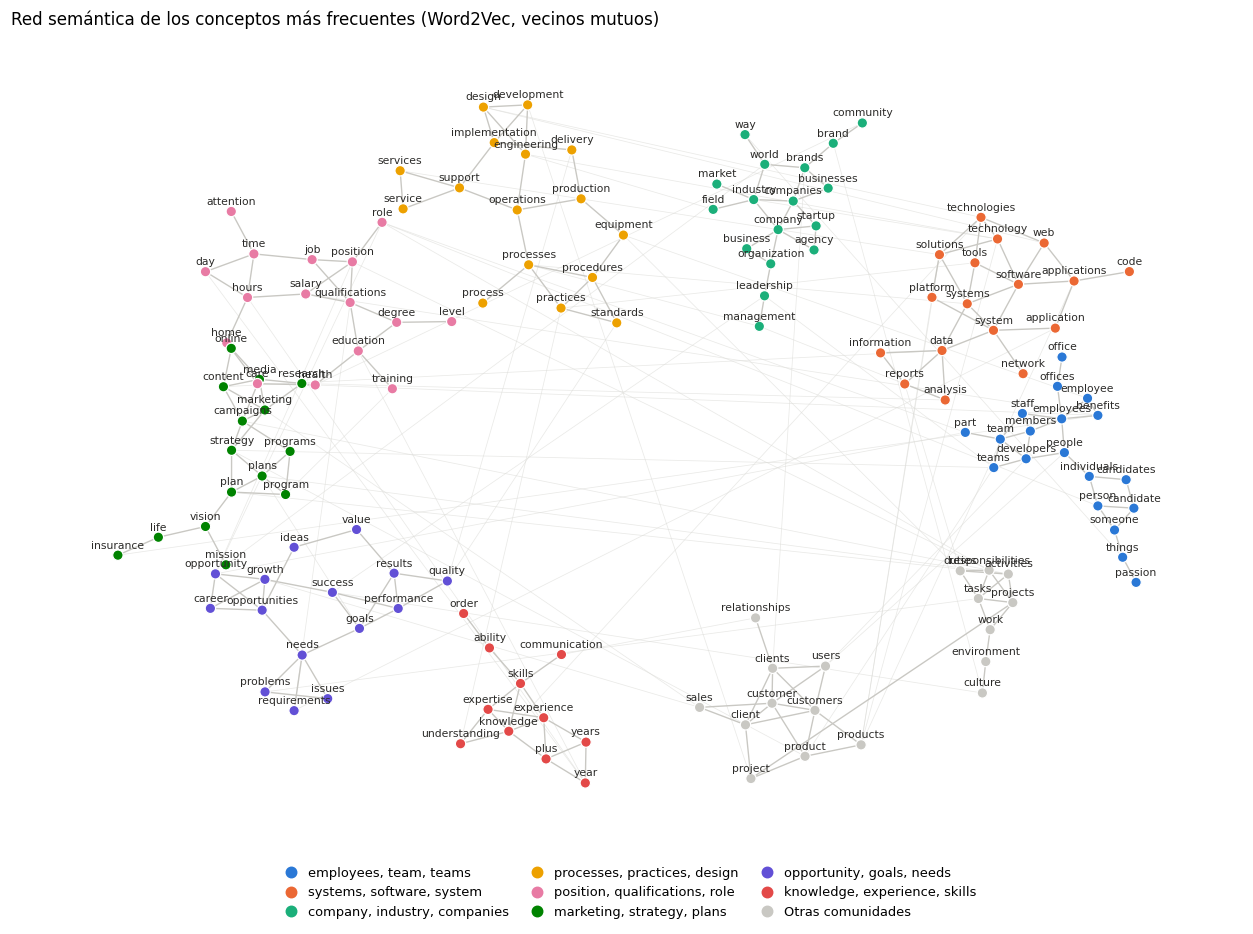

In [13]:
color_de = {}
for i, c in enumerate(comunidades):
    for w in c:
        color_de[w] = SERIES[i] if i < len(SERIES) else TENUE
# Cada comunidad se acomoda por separado alrededor de una elipse, para que se pueda leer.
posicion = {}
for i, c in enumerate(comunidades):
    angulo = 2 * np.pi * i / len(comunidades)
    centro = np.array([3.3 * np.cos(angulo), 2.5 * np.sin(angulo)])
    sub = nx.kamada_kawai_layout(red.subgraph(c), weight=None)
    for w, xy in sub.items():
        posicion[w] = centro + xy * 1.05 * np.sqrt(len(c) / 15)

fig, ax = plt.subplots(figsize=(11.5, 8.6))
internos = [(a, b) for a, b in red.edges if color_de[a] == color_de[b]]
externos = [(a, b) for a, b in red.edges if color_de[a] != color_de[b]]
nx.draw_networkx_edges(red, posicion, ax=ax, edgelist=externos, edge_color=REJILLA, width=0.5, alpha=0.6)
nx.draw_networkx_edges(red, posicion, ax=ax, edgelist=internos, edge_color=TENUE, width=0.9)
nx.draw_networkx_nodes(red, posicion, ax=ax, node_size=46, linewidths=0.8, edgecolors="white",
                       node_color=[color_de[w] for w in red.nodes])
for w, (x, y) in posicion.items():
    ax.annotate(w, (x, y), xytext=(0, 5), textcoords="offset points", ha="center", fontsize=7, color="#2b2a28")
for i, c in enumerate(comunidades[:len(SERIES)]):
    orden = sorted(c, key=lambda w: -red.degree(w, weight="weight"))
    ax.scatter([], [], s=46, color=SERIES[i], label=", ".join(orden[:3]))
if len(comunidades) > len(SERIES):
    ax.scatter([], [], s=46, color=TENUE, label="Otras comunidades")
ax.legend(loc="upper center", bbox_to_anchor=(0.5, 0.0), ncol=3, handletextpad=0.3, columnspacing=1.2)
ax.set_title("Red semántica de los conceptos más frecuentes (Word2Vec, vecinos mutuos)", loc="left")
ax.axis("off")
fig.tight_layout()
plt.show()

Nadie le dijo al modelo qué temas existen, y aun así la red se organiza en grupos con sentido (la
modularidad de 0.69 indica que las comunidades están bien separadas). Hay una comunidad de personas
(`employees`, `team`, `candidate`), una de tecnología, una de empresa y marca, una de marketing y una
de clientes. La comunidad roja reúne el vocabulario de los requisitos (`knowledge`, `experience`,
`skills`, `years`), y la rosa el del puesto y sus condiciones (`position`, `salary`, `hours`, `degree`).

Se nota lo que aprendió del corpus: `benefits` queda en la comunidad de personas, junto a `employees`,
porque en los anuncios las prestaciones siempre se le ofrecen a alguien. `health`, `care` y `home`
quedan unidas, y esa conexión anticipa el sentido de `home` que aparece en la sección 4. Los conceptos
puente, que conectan comunidades, son palabras generales como `industry`, `technology` y `position`.

### 3.2 Los personajes del anuncio y los lugares

Para ubicar los roles construyo dos ejes de significado. Cada eje es la resta entre dos grupos de
palabras: uno va de `customers, patients, clients, people` a `software, code, technical, systems`, y
el otro de `junior, entry-level, graduate, apprentice` a `senior, lead, executive, experienced`.
Después proyecto cada rol sobre los ejes. Las palabras de los polos no están en la lista de roles,
para no forzar el resultado.

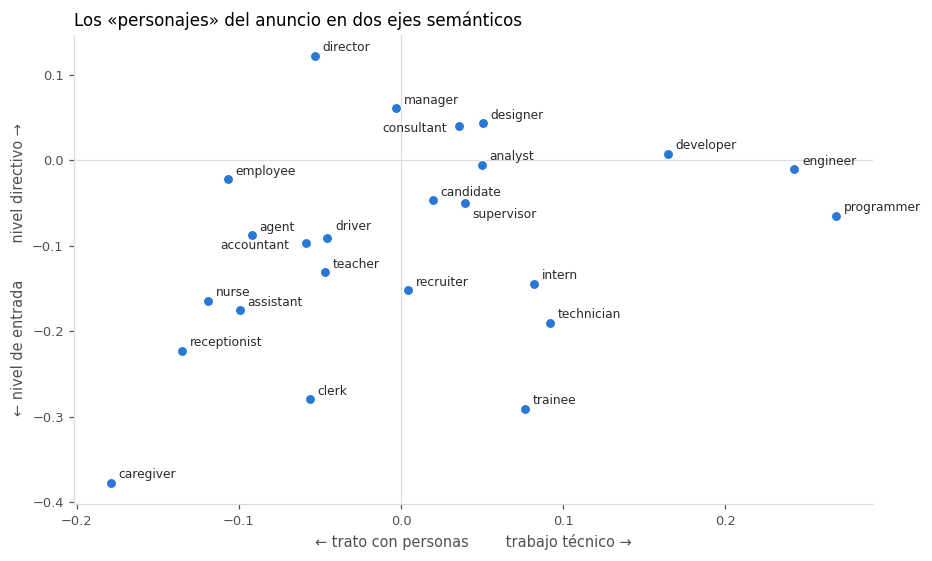

Lugares y sus vecinos en el corpus:
  greece    aegean, cyprus, vodafone, airlines, atcom, turkey
  athens    athens_greece, thessaloniki, ogilvyone, copenhagen, kreuzberg, berlin
  london    berlin, sydney, tokyo, glasgow, helsinki, madrid
  houston   texas, raleigh, dallas, bakersfield, houston_tx, illinois
  germany   spain, austria, netherlands, poland, france, belgium
  india     americas, vietnam, sydney, shanghai, malaysia, latin_america


In [14]:
ROLES = ["developer", "engineer", "programmer", "analyst", "designer", "technician", "consultant", "accountant",
         "nurse", "caregiver", "teacher", "driver", "clerk", "receptionist", "assistant", "agent",
         "recruiter", "supervisor", "director", "manager", "intern", "trainee", "candidate", "employee"]
ROLES = [r for r in ROLES if r in w2v]

def eje(polo_a, polo_b):
    return unitario(np.mean([unitario(w2v[w]) for w in polo_a], axis=0)
                    - np.mean([unitario(w2v[w]) for w in polo_b], axis=0))

# Los polos usan palabras que no están en la lista de roles, para no forzar el resultado.
eje_tecnico = eje(["software", "code", "technical", "systems"], ["customers", "patients", "clients", "people"])
eje_nivel = eje(["senior", "lead", "executive", "experienced"], ["junior", "entry-level", "graduate", "apprentice"])
x = np.array([unitario(w2v[r]) @ eje_tecnico for r in ROLES])
y = np.array([unitario(w2v[r]) @ eje_nivel for r in ROLES])

fig, ax = plt.subplots(figsize=(8.6, 5.2))
ax.axhline(0, color=REJILLA, lw=0.8)
ax.axvline(0, color=REJILLA, lw=0.8)
ax.scatter(x, y, s=44, color=AZUL, edgecolors="white", linewidths=0.8, zorder=3)
AJUSTE = {"consultant": (-50, -4), "supervisor": (5, -10), "accountant": (-56, -4), "driver": (5, 5)}
for r, a, b in zip(ROLES, x, y):
    ax.annotate(r, (a, b), xytext=AJUSTE.get(r, (5, 3)), textcoords="offset points", fontsize=8, color="#2b2a28")
ax.set_xlabel("← trato con personas        trabajo técnico →")
ax.set_ylabel("← nivel de entrada        nivel directivo →")
ax.set_title("Los «personajes» del anuncio en dos ejes semánticos", loc="left")
estilizar(ax, None)
fig.tight_layout()
plt.show()

print("Lugares y sus vecinos en el corpus:")
for lugar in ["greece", "athens", "london", "houston", "germany", "india"]:
    print(f"  {lugar:<9} {', '.join(w for w, _ in w2v.most_similar(lugar, topn=6))}")

El eje horizontal funciona bien: `programmer`, `engineer` y `developer` quedan claramente a la
derecha, y `caregiver`, `receptionist`, `nurse` y `employee` a la izquierda. El vertical también es
razonable, con `director` y `manager` arriba y `trainee` y `clerk` abajo. `caregiver` queda en el
extremo inferior, y eso no significa que sea un trabajo sencillo: refleja que estos anuncios piden
poca experiencia. El mapa muestra cómo habla de cada rol este corpus, no cómo es el rol en realidad.

Los lugares confirman esto mismo. `germany` queda con otros países europeos y `houston` con ciudades
de Estados Unidos, como cabría esperar. Pero `greece` tiene como vecinos a `aegean`, `vodafone` y
`airlines`, que son empresas. Esto refleja lo que encontré en la Práctica 1: el dataset se recolectó
en Grecia, y aquí "Grecia" significa las empresas griegas que publicaron anuncios.

### 3.3 Comparación entre industrias

Aquí paso a MiniLM. Calculo el centroide de cada industria con sus ofertas legítimas. Le resto el
promedio general, porque todos los anuncios se parecen entre sí y sin este paso todos los cosenos
quedarían cerca de 1.

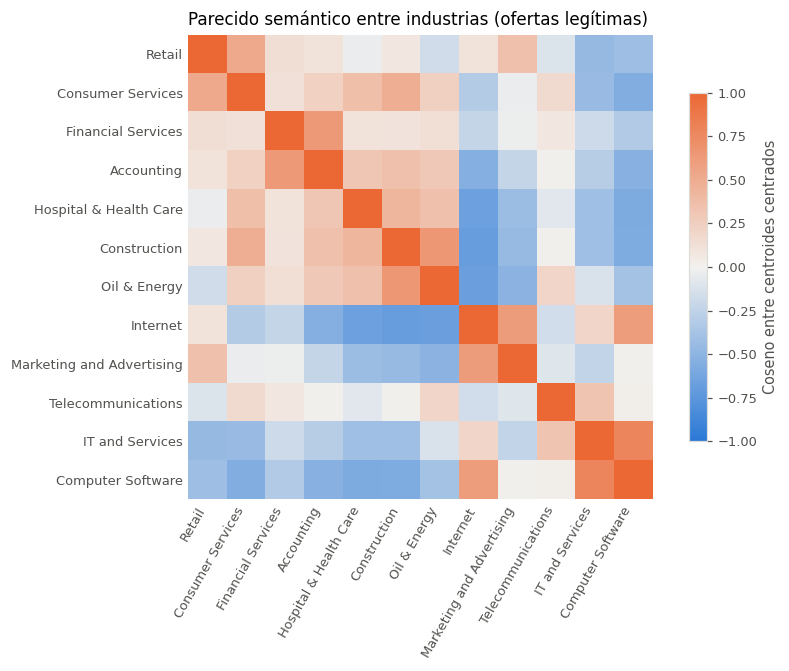

                          Fraude en  n fraude  n legítimas  coseno con su industria  lugar industria legítima más cercana
                       Oil & Energy        66           90                     0.78      1                   Oil & Energy
                         Accounting        39           58                     0.67      1                     Accounting
             Hospital & Health Care        33          210                     0.88      1         Hospital & Health Care
Information Technology and Services        30         1213                     0.64      1                IT and Services
          Marketing and Advertising        29          477                     0.28      1      Marketing and Advertising


In [15]:
rep_mask = np.zeros(len(docs), dtype=bool)
rep_mask[representantes] = True
conteo = docs.loc[(~fraude) & rep_mask & (docs["industria"] != "(sin industria)"), "industria"].value_counts()
top_fraude = docs.loc[fraude & rep_mask & (docs["industria"] != "(sin industria)"), "industria"].value_counts()
INDUSTRIAS = list(dict.fromkeys(list(conteo.head(11).index) + list(top_fraude.head(5).index)))
centro_global = D[rep_mask].mean(0)
centroides = np.array([D[rep_mask & ~fraude & (docs["industria"] == i).to_numpy()].mean(0) - centro_global
                       for i in INDUSTRIAS])
M = unitario(centroides) @ unitario(centroides).T
orden = leaves_list(linkage(centroides, "average", metric="cosine"))
nombres = [corto(INDUSTRIAS[i]) for i in orden]

fig, ax = plt.subplots(figsize=(8.2, 6.2))
im = ax.imshow(M[np.ix_(orden, orden)], cmap=DIVERGENTE, vmin=-1, vmax=1)
ax.set_xticks(range(len(nombres)), nombres, rotation=60, ha="right")
ax.set_yticks(range(len(nombres)), nombres)
ax.tick_params(length=0)
for s in ax.spines.values():
    s.set_visible(False)
fig.colorbar(im, ax=ax, shrink=0.75, label="Coseno entre centroides centrados")
ax.set_title("Parecido semántico entre industrias (ofertas legítimas)", loc="left")
fig.tight_layout()
plt.show()

filas = []
for industria in top_fraude.head(5).index:
    en_ind = (docs["industria"] == industria).to_numpy() & rep_mask
    cf = D[en_ind & fraude].mean(0)
    sims = {i: coseno(cf - centro_global, D[rep_mask & ~fraude & (docs["industria"] == i).to_numpy()].mean(0) - centro_global)
            for i in INDUSTRIAS}
    orden_s = sorted(sims, key=sims.get, reverse=True)
    filas.append((industria, int((en_ind & fraude).sum()), int((en_ind & ~fraude).sum()),
                  round(sims[industria], 2), orden_s.index(industria) + 1, corto(orden_s[0])))
print(pd.DataFrame(filas, columns=["Fraude en", "n fraude", "n legítimas", "coseno con su industria",
                                   "lugar", "industria legítima más cercana"]).to_string(index=False))

El mapa forma dos bloques opuestos. En el mundo digital quedan `Computer Software`, `IT and Services`,
`Internet` y, cerca, `Marketing and Advertising`. En el de operaciones físicas y servicios quedan
`Construction`, `Oil & Energy`, `Hospital & Health Care` y `Accounting`, con `Financial Services`
junto a `Accounting`. Es una división más útil que los nombres oficiales de las industrias, porque
muestra qué sectores usan un lenguaje realmente parecido.

La tabla responde a una pregunta directa: ¿una oferta falsa de un sector habla como las legítimas de
ese sector? **Sí, en los cinco casos** la industria legítima más cercana es la suya. Las estafas imitan
el lenguaje del sector. Por eso comparar el fraude contra todo el corpus mide sobre todo el tema, y
de ahí que deba controlarlo. *Marketing* tiene el coseno más bajo (0.28), aunque sigue en primer lugar.

### 3.4 ¿Las ofertas falsas se parecen entre sí?

Busco los 10 vecinos más cercanos de cada oferta falsa y mido cuántos también son falsos. La prueba se
endurece por pasos:

1. Sin excluir nada.
2. Dentro de su industria y sin contar su propia campaña.
3. Además, excluyendo cualquier vecino con el que comparta una oración de 6 palabras o más.

El valor p viene de revolver las etiquetas 1,000 veces dentro de cada industria y corresponde a la
prueba más dura.

Global, sin excluir nada: 0.497 (tasa base 0.048)

                           Ofertas  Fraude  Tasa base  Sin campaña  Sin oraciones comunes  Vecinos de legítimas      p
Industria                                                                                                             
Oil & Energy                   237     107      0.451        0.864                  0.593                 0.233  0.002
Accounting                     118      46      0.390        0.620                  0.604                 0.225  0.001
Hospital & Health Care         417      43      0.103        0.388                  0.379                 0.018  0.001
IT and Services               1572      32      0.020        0.109                  0.059                 0.024  0.002
Marketing and Advertising      696      36      0.052        0.417                  0.036                 0.018  0.825
(sin industria)               4149     202      0.049        0.353                  0.319                 0.022  0.0

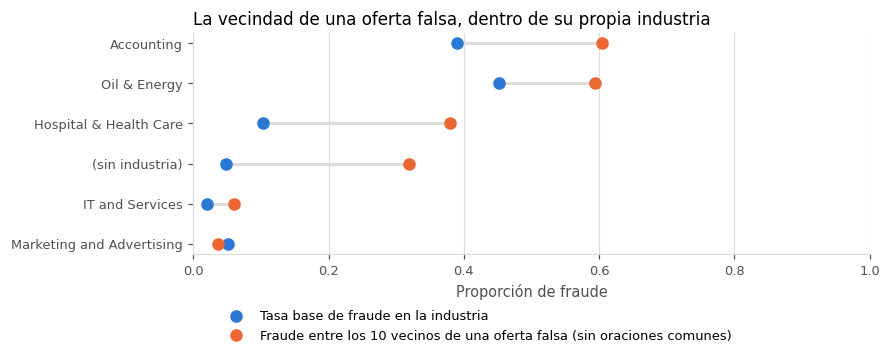

In [16]:
# Matriz documento x oración para saber qué ofertas comparten alguna oración de 6 palabras o más.
largas = oraciones[oraciones["oracion"].str.split().str.len() >= 6].drop_duplicates(["doc", "uid"])
B = csr_matrix((np.ones(len(largas), dtype=np.float32), (largas["doc"], largas["uid"])),
               shape=(len(docs), len(unicas)))

def pureza(indices, excluir_oraciones, k=10, permutaciones=1000):
    S = D[indices] @ D[indices].T
    S[campana[indices][:, None] == campana[indices][None, :]] = -2
    if excluir_oraciones:
        S[(B[indices] @ B[indices].T).toarray() > 0] = -2
    top = np.argsort(-S, axis=1)[:, :k]
    valido = np.take_along_axis(S, top, 1) > -2
    f = fraude[indices]
    medir = lambda y: (y[top] * valido).sum(1)[y].sum() / max(valido[y].sum(), 1)
    observada = medir(f)
    nula = [medir(rng.permutation(f)) for _ in range(permutaciones)]
    return observada, (y := (f[top[~f]] * valido[~f]).sum() / max(valido[~f].sum(), 1)), \
        (1 + sum(n >= observada for n in nula)) / (permutaciones + 1)

filas = []
for industria in list(top_fraude.head(5).index) + ["(sin industria)"]:
    indices = np.where((docs["industria"] == industria).to_numpy())[0]
    f = fraude[indices]
    sin_camp, legit, p1 = pureza(indices, False)
    sin_orac, _, p2 = pureza(indices, True)
    filas.append((corto(industria), len(indices), f.sum(), f.mean(), sin_camp, sin_orac, legit, p2))
tabla_pureza = pd.DataFrame(filas, columns=["Industria", "Ofertas", "Fraude", "Tasa base", "Sin campaña",
                                            "Sin oraciones comunes", "Vecinos de legítimas", "p"]).set_index("Industria")
print(f"Global, sin excluir nada: {fraude[vecinos[fraude, :10]].mean():.3f} (tasa base {fraude.mean():.3f})\n")
print(tabla_pureza.round(3).to_string())

fig, ax = plt.subplots(figsize=(8.2, 3.5))
t = tabla_pureza.sort_values("Sin oraciones comunes")
y = np.arange(len(t))
ax.hlines(y, t["Tasa base"], t["Sin oraciones comunes"], color=REJILLA, lw=2)
ax.scatter(t["Tasa base"], y, s=52, color=AZUL, zorder=3, label="Tasa base de fraude en la industria")
ax.scatter(t["Sin oraciones comunes"], y, s=52, color=NARANJA, zorder=3,
           label="Fraude entre los 10 vecinos de una oferta falsa (sin oraciones comunes)")
ax.set_yticks(y, t.index)
ax.set_xlim(0, 1)
ax.set_xlabel("Proporción de fraude")
ax.legend(loc="upper center", bbox_to_anchor=(0.42, -0.2), ncol=1)
ax.set_title("La vecindad de una oferta falsa, dentro de su propia industria", loc="left")
estilizar(ax, "x")
fig.tight_layout()
plt.show()

Sin ningún control el resultado parece espectacular: la mitad de los vecinos de una oferta falsa
también son falsos, contra una tasa base de 4.8 %. Con los controles se ve qué parte era real:

- **Marketing:** la señal desaparece. Pasa de 0.42 a 0.04, por debajo de la tasa base (p = 0.82). Lo
  que parecía parecido entre ofertas falsas eran oraciones copiadas, o sea plantillas.
- **Oil & Energy:** baja mucho, de 0.86 a 0.59, con una tasa base de 0.45.
- **Accounting y Hospital & Health Care:** casi no cambia (0.60 y 0.38). Aquí las ofertas falsas se
  parecen entre sí sin compartir oraciones. En salud es casi cuatro veces la tasa base.
- **Sin industria:** se mantiene alto (0.32 contra 0.05). Este grupo no se puede controlar por tema,
  porque no sabemos a qué sector pertenecen.
- **IT and Services:** queda un efecto pequeño (0.06 contra 0.02).

La conclusión es que **no hay un "estilo de fraude" universal**. En algunos sectores las ofertas falsas
forman una región propia del espacio semántico y en otros no. También es posible que parte de lo que
queda sean plantillas reescritas que comparten ideas pero no oraciones exactas, y este análisis no
puede distinguir eso.

### 3.5 ¿Los conceptos típicos de una estafa distinguen al fraude?

Si pensamos en una estafa de empleo, vienen a la mente "trabaja desde casa", "gana mucho" o "manda tus
datos bancarios". Puedo buscar esas ideas por significado y no por palabras clave. Escribí ocho
conceptos **antes** de mirar los resultados: seis ideas típicas de estafa y dos de una empresa formal.
El puntaje de cada oferta es la similitud máxima entre el concepto y cualquiera de sus oraciones.

Hay una trampa: un anuncio largo tiene más oportunidades de acercarse a un concepto, y las ofertas
falsas son más cortas. Por eso comparo cada oferta falsa solo con legítimas de longitud parecida.
La medida es el AUC: la probabilidad de que una oferta falsa tenga un puntaje mayor que una legítima.
Un valor de 0.5 significa que no distingue nada.

Trabajo desde casa      Earn Money Working From Home | Work From Home (Easy Money)
Sin experiencia         No experience required, we provide full trai | We provide you with full training - no exper
Ingresos altos          GET PAID WEEKLY | High hourly pay, paid weekly
Contratación urgente    Hiring immediately | Position is open for immediate hiring.


Datos y banco           Take payment information and other pertinent | Collects information required about the acco
Postulación directa     Email your resume to | email your resumes to
Historia de la empresa  Our company is profitable and established. | We are a young company founded by very exper
Seguro y vacaciones     Paid vacation (with tickets out and home), h | Full health benefits plus paid vacation
Mediana de oraciones por oferta: fraude 22, legítimas 28



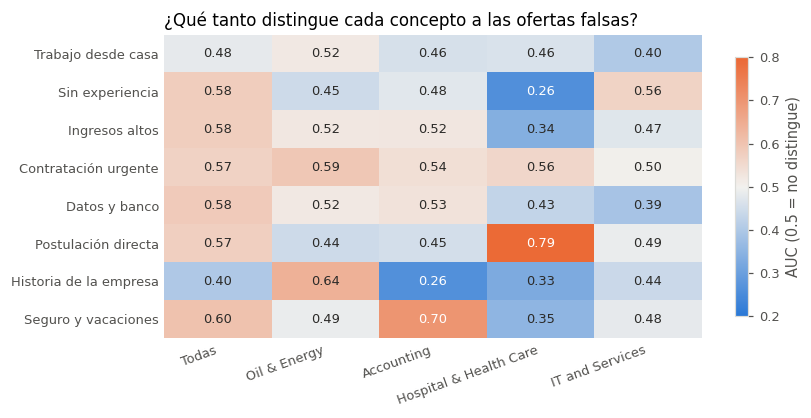

In [17]:
HIPOTESIS = {
    "Trabajo desde casa": "Work from home and earn money online",
    "Sin experiencia": "No experience is required, we provide full training",
    "Ingresos altos": "Earn a high income with weekly pay",
    "Contratación urgente": "Urgent hiring, immediate start",
    "Datos y banco": "Provide your bank account and personal information",
    "Postulación directa": "Send your resume by email to apply immediately",
    "Historia de la empresa": "Our company was founded many years ago and is a leader in the industry",
    "Seguro y vacaciones": "Health insurance and paid vacation",
}
Q = sbert.encode(list(HIPOTESIS.values()), normalize_embeddings=True)
sim_u = E @ Q.T
for nombre, col in zip(HIPOTESIS, sim_u.T):
    print(f"{nombre:<23} {' | '.join(unicas[i][:44] for i in np.argsort(-col)[:2])}")

# Un anuncio largo tiene más oportunidades de acercarse a un concepto, y los falsos son más cortos.
# Por eso cada oferta falsa se compara solo con legítimas de longitud parecida.
n_oraciones = oraciones.groupby("doc").size().reindex(range(len(docs))).fillna(0).to_numpy()
longitud = pd.qcut(n_oraciones[rep_mask], 4, labels=False, duplicates="drop")
LONGITUD = np.zeros(len(docs), dtype=int)
LONGITUD[rep_mask] = longitud
print(f"Mediana de oraciones por oferta: fraude {np.median(n_oraciones[fraude]):.0f}, "
      f"legítimas {np.median(n_oraciones[~fraude]):.0f}\n")

def auc_por_longitud(y, s, estratos):
    suma = peso = 0.0
    for e in np.unique(estratos):
        k = estratos == e
        pares = y[k].sum() * (~y[k]).sum()
        if pares:
            suma += pares * roc_auc_score(y[k], s[k])
            peso += pares
    return suma / peso

puntaje = pd.DataFrame(sim_u[oraciones["uid"].to_numpy()], columns=list(HIPOTESIS))
puntaje["doc"] = oraciones["doc"].to_numpy()
puntaje = puntaje.groupby("doc").max().reindex(range(len(docs)))

columnas = ["Todas"] + [i for i in top_fraude.head(4).index]
A = np.zeros((len(HIPOTESIS), len(columnas)))
for r, h in enumerate(HIPOTESIS):
    A[r, 0] = auc_por_longitud(fraude[rep_mask], puntaje[h].to_numpy()[rep_mask], LONGITUD[rep_mask])
    for c, industria in enumerate(columnas[1:], 1):
        k = rep_mask & (docs["industria"] == industria).to_numpy()
        A[r, c] = auc_por_longitud(fraude[k], puntaje[h].to_numpy()[k], LONGITUD[k])

fig, ax = plt.subplots(figsize=(7.8, 3.9))
im = ax.imshow(A, cmap=DIVERGENTE, vmin=0.2, vmax=0.8, aspect="auto")
ax.set_xticks(range(len(columnas)), [corto(c) for c in columnas], rotation=20, ha="right")
ax.set_yticks(range(len(HIPOTESIS)), list(HIPOTESIS))
ax.tick_params(length=0)
for s in ax.spines.values():
    s.set_visible(False)
for r in range(A.shape[0]):
    for c in range(A.shape[1]):
        ax.text(c, r, f"{A[r, c]:.2f}", ha="center", va="center", fontsize=8.5,
                color="white" if abs(A[r, c] - 0.5) > 0.2 else "#2b2a28")
fig.colorbar(im, ax=ax, shrink=0.85, label="AUC (0.5 = no distingue)")
ax.set_title("¿Qué tanto distingue cada concepto a las ofertas falsas?", loc="left")
fig.tight_layout()
plt.show()

La búsqueda funciona bien, como muestran las oraciones que encuentra. Lo que falla es la hipótesis:
**ningún concepto se sale del rango de 0.40 a 0.60 en todo el corpus**. `Trabajo desde casa` da 0.48, es decir, no
distingue nada, porque también hay muchas ofertas legítimas de trabajo remoto. `Datos y banco`
tampoco sirve: las oraciones más cercanas son tareas normales de oficina, así que estos anuncios no
piden datos bancarios de forma explícita. Tiene sentido, porque eso se pediría después, en el contacto
directo.

Además, los valores cambian de sentido según la industria. `Seguro y vacaciones` (0.60) e `Historia
de la empresa` (0.40) son lo que más se aleja de 0.5, y ninguno es consistente. El primero llega a
0.70 en *Accounting* y baja a 0.35 en salud. El segundo indica que las falsas hablan menos de la
empresa, pero en *Oil & Energy* se invierte a 0.64: ahí hablan más de ella que las legítimas, lo cual
es coherente con ofertas que imitan a compañías petroleras. Valores extremos como `Postulación directa` en salud (0.79) salen de solo 33 ofertas.

### 3.6 Temas descubiertos sin hipótesis

Para no depender de lo que yo imaginé, dejo que los datos propongan los temas. Agrupo las 242,696
oraciones únicas en 20 grupos con k-means sobre los vectores de MiniLM, y los nombro con sus tres
palabras más características.

Para comparar uso la **razón de momios de Mantel-Haenszel**, que resume la asociación dentro de cada
combinación de industria y longitud del anuncio. Un valor de 2 significa que las posibilidades de que
aparezca el tema se duplican en una oferta falsa. Los valores p se corrigen por comparaciones múltiples.

                           Tema  Fraude  Legítima  OR cruda  OR ajustada  p FDR
    experience, web, javascript   0.098     0.385     0.173        0.284  0.000
       marketing, media, social   0.150     0.468     0.200        0.291  0.000
     english, language, written   0.108     0.249     0.364        0.433  0.000
        business, sales, client   0.341     0.529     0.461        0.465  0.000
            team, work, looking   0.455     0.706     0.347        0.466  0.000
     project, team, development   0.325     0.509     0.466        0.643  0.001
       sales, business, company   0.415     0.550     0.582        0.693  0.003
  experience, software, systems   0.453     0.612     0.525        0.775  0.034
      experience, years, degree   0.617     0.643     0.895        0.962  0.901
       ability, attention, work   0.471     0.547     0.737        0.978  0.985
   experience, skills, software   0.553     0.634     0.713        1.004  1.000
          data, experience, sql   0.317 

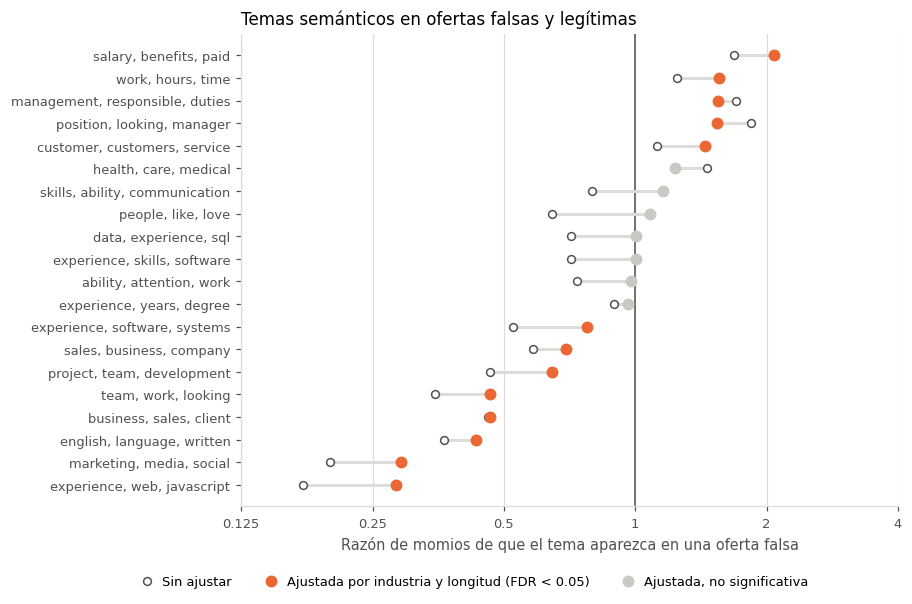

In [18]:
K_TEMAS = 20
agrupador = MiniBatchKMeans(K_TEMAS, random_state=SEMILLA, batch_size=4096, n_init=5).fit(E)
tema_u = agrupador.labels_
oraciones["tema"] = tema_u[oraciones["uid"].to_numpy()]

por_tema = pd.Series(unicas).groupby(tema_u).apply(" ".join)
cv = CountVectorizer(stop_words="english", min_df=2, token_pattern=r"[a-z][a-z+#-]+")
peso = TfidfTransformer().fit_transform(cv.fit_transform(por_tema)).toarray()
vocabulario_t = cv.get_feature_names_out()
ETIQUETA = {t: ", ".join(vocabulario_t[np.argsort(-peso[t])[:3]]) for t in range(K_TEMAS)}

def cmh(expuesto, evento, estratos):
    # Prueba de Cochran-Mantel-Haenszel y razón de momios común para tablas 2x2 por estrato.
    num = den = dif = var = 0.0
    for e in np.unique(estratos):
        k = estratos == e
        a = (expuesto[k] & evento[k]).sum(); b = (expuesto[k] & ~evento[k]).sum()
        c = (~expuesto[k] & evento[k]).sum(); d = (~expuesto[k] & ~evento[k]).sum()
        n = a + b + c + d
        if n < 2 or (a + b) == 0 or (c + d) == 0:
            continue
        num += a * d / n; den += b * c / n
        dif += a - (a + b) * (a + c) / n
        var += (a + b) * (c + d) * (a + c) * (b + d) / (n * n * (n - 1))
    p = chi2.sf(max(abs(dif) - 0.5, 0) ** 2 / var, 1) if var > 0 else 1.0
    return (num / den if den > 0 else np.nan), p

presencia = pd.crosstab(oraciones["doc"], oraciones["tema"]).gt(0).reindex(range(len(docs)), fill_value=False)
estrato_rep = docs["industria"].to_numpy()[representantes] + "|" + LONGITUD[representantes].astype(str)
filas = []
for t in range(K_TEMAS):
    p = presencia[t].to_numpy()[representantes]
    razon, valor_p = cmh(fr_rep, p, estrato_rep)
    filas.append((ETIQUETA[t], p[fr_rep].mean(), p[~fr_rep].mean(), razon, valor_p))
temas = pd.DataFrame(filas, columns=["Tema", "Fraude", "Legítima", "OR ajustada", "p"])
temas["OR cruda"] = (temas["Fraude"] / (1 - temas["Fraude"])) / (temas["Legítima"] / (1 - temas["Legítima"]))
temas["p FDR"] = false_discovery_control(temas["p"].to_numpy())
temas = temas.sort_values("OR ajustada")
print(temas[["Tema", "Fraude", "Legítima", "OR cruda", "OR ajustada", "p FDR"]].round(3).to_string(index=False))

fig, ax = plt.subplots(figsize=(8.4, 5.6))
y = np.arange(len(temas))
sig = temas["p FDR"] < 0.05
ax.axvline(1, color=GRIS, lw=1)
ax.hlines(y, temas["OR cruda"], temas["OR ajustada"], color=REJILLA, lw=2)
ax.scatter(temas["OR cruda"], y, s=26, facecolors="white", edgecolors=GRIS, zorder=3, label="Sin ajustar")
ax.scatter(temas["OR ajustada"][sig], y[sig], s=46, color=NARANJA, zorder=4, label="Ajustada por industria y longitud (FDR < 0.05)")
ax.scatter(temas["OR ajustada"][~sig], y[~sig], s=46, color=TENUE, zorder=4, label="Ajustada, no significativa")
ax.set_xscale("log")
ax.set_xticks([0.125, 0.25, 0.5, 1, 2, 4], ["0.125", "0.25", "0.5", "1", "2", "4"])
ax.minorticks_off()
ax.set_yticks(y, temas["Tema"])
ax.set_xlabel("Razón de momios de que el tema aparezca en una oferta falsa")
ax.legend(loc="upper center", bbox_to_anchor=(0.35, -0.12), ncol=3, handletextpad=0.2)
ax.set_title("Temas semánticos en ofertas falsas y legítimas", loc="left")
estilizar(ax, "x")
fig.tight_layout()
plt.show()

Los círculos vacíos son el resultado sin ajustar y los puntos, el ajustado. Sin control, casi todo
parecía menos frecuente en el fraude, pero en buena parte eso se debía a que sus anuncios son más
cortos. Con el ajuste el cuadro queda más equilibrado y más claro:

- **Más presentes en ofertas falsas:** condiciones de pago (`salary, benefits, paid`, 2.08), horarios
  (`work, hours, time`, 1.56), funciones generales del puesto (`management, responsible, duties`, 1.55),
  y atención a clientes (`customer, service`, 1.45).
- **Menos presentes:** tecnología concreta (`experience, web, javascript`, 0.28), marketing digital
  (0.29), idiomas (0.43), y el lenguaje de equipo y cultura (`team, work, looking`, 0.47).

La imagen es consistente: la oferta falsa habla de **lo que vas a recibir** y de un puesto genérico, y
habla menos del equipo y de los conocimientos específicos. Esto tiene sentido, porque escribir
requisitos técnicos creíbles exige conocer el trabajo de verdad, mientras que prometer un sueldo no.
El fraude no se delata por ideas sospechosas, sino por la falta de detalle.

## 4. Evolución del significado dentro del texto

Un anuncio avanza de una sección a otra: se presenta la empresa, se describe el puesto, se piden
requisitos y se ofrecen prestaciones. Aquí analizo cómo cambia el significado a lo largo de ese
recorrido, en cuatro niveles: las secciones, los temas, las palabras y las oraciones vecinas.

### 4.1 Las secciones en el espacio semántico

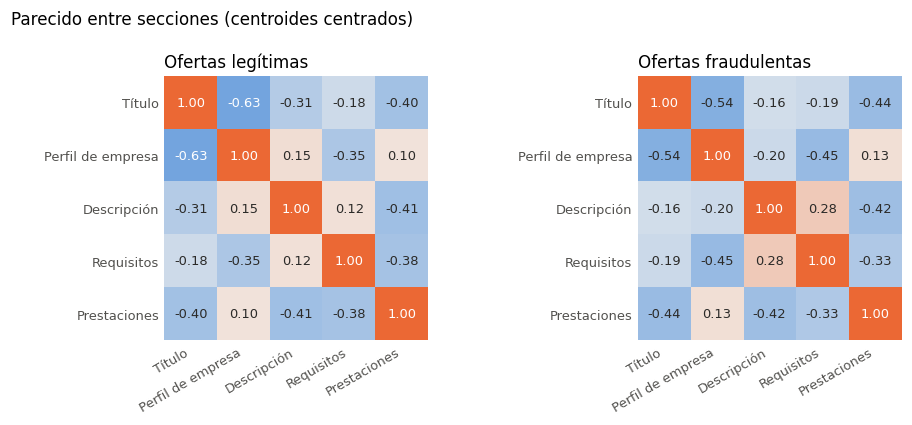

Correlación entre las dos estructuras: 0.85


In [19]:
unicos_sec = oraciones.drop_duplicates(["uid", "seccion", "categoria"])
C = {(s, c): E[unicos_sec[(unicos_sec["seccion"] == s) & (unicos_sec["categoria"] == c)]["uid"].to_numpy()].mean(0)
     for s in SECCIONES for c in ["Legítima", "Fraudulenta"]}
# Cada categoría se centra con su propia media, para comparar su estructura interna.
for cat in ["Legítima", "Fraudulenta"]:
    media = np.mean([C[(s, cat)] for s in SECCIONES], axis=0)
    for s in SECCIONES:
        C[(s, cat)] = C[(s, cat)] - media

fig, ejes = plt.subplots(1, 2, figsize=(8.8, 3.9))
for ax, cat in zip(ejes, ["Legítima", "Fraudulenta"]):
    M = unitario(np.array([C[(s, cat)] for s in SECCIONES]))
    M = M @ M.T
    im = ax.imshow(M, cmap=DIVERGENTE, vmin=-1, vmax=1)
    nombres = [NOMBRE_SEC[s] for s in SECCIONES]
    ax.set_xticks(range(5), nombres, rotation=30, ha="right")
    ax.set_yticks(range(5), nombres)
    ax.tick_params(length=0)
    for s in ax.spines.values():
        s.set_visible(False)
    for i in range(5):
        for j in range(5):
            ax.text(j, i, f"{M[i, j]:.2f}", ha="center", va="center", fontsize=8.5,
                    color="white" if abs(M[i, j]) > 0.6 else "#2b2a28")
    ax.set_title(f"Ofertas {cat.lower().replace('legítima', 'legítimas').replace('fraudulenta', 'fraudulentas')}", loc="left")
fig.suptitle("Parecido entre secciones (centroides centrados)", fontsize=11, x=0.02, ha="left")
fig.tight_layout()
plt.show()
M_l = unitario(np.array([C[(s, "Legítima")] for s in SECCIONES]))
M_f = unitario(np.array([C[(s, "Fraudulenta")] for s in SECCIONES]))
iu = np.triu_indices(5, 1)
print(f"Correlación entre las dos estructuras: {np.corrcoef((M_l @ M_l.T)[iu], (M_f @ M_f.T)[iu])[0, 1]:.2f}")

Cada categoría está centrada con su propia media, así que aquí comparo la forma de la estructura y no
la posición absoluta. Las dos matrices se parecen mucho (correlación 0.85): **los anuncios falsos
imitan bien la estructura de un anuncio real**. En ambos casos el título queda lejos de todo, porque
es muy corto, y el perfil de empresa se acerca a prestaciones (0.10 y 0.13), ya que las dos secciones
hablan de la empresa y no del puesto.

Hay dos diferencias. En las legítimas el perfil de empresa se conecta con la descripción (0.15), y en
las falsas no (−0.20): la presentación de la empresa va por un lado y el puesto por otro. Además,
descripción y requisitos están más unidos en las falsas (0.28 contra 0.12), así que esas dos secciones
se distinguen menos. Hay que tomarlo con cautela, porque solo una de cada tres ofertas falsas tiene
perfil de empresa.

Ahora comparo el contenido de cada sección entre falsas y legítimas, dentro de cada industria y con
una oferta por campaña. Las diferencias se comparan con lo que daría el azar, revolviendo las etiquetas.

In [20]:
def distancia_ajustada(seccion, permutaciones=1000):
    # Compara fraude y legítimas dentro de cada industria y promedia las diferencias.
    q = oraciones[(oraciones["seccion"] == seccion) & oraciones["doc"].isin(representantes)]
    A = np.zeros((len(docs), 384), dtype=np.float32)
    n = np.zeros(len(docs))
    np.add.at(A, q["doc"].to_numpy(), E[q["uid"].to_numpy()])
    np.add.at(n, q["doc"].to_numpy(), 1)
    tiene = n > 0
    grupos = []
    for industria, g in docs[tiene].groupby("industria"):
        idx = g.index.to_numpy()
        if fraude[idx].sum() >= 5 and (~fraude[idx]).sum() >= 5:
            grupos.append((A[idx] / n[idx, None], fraude[idx]))
    def medir(etiquetas):
        peso_total = sum(y.sum() for _, y in grupos)
        dif = sum(y0.sum() * (X[y].mean(0) - X[~y].mean(0)) for (X, y0), y in zip(grupos, etiquetas))
        return np.linalg.norm(dif / peso_total)
    observada = medir([y for _, y in grupos])
    nula = np.array([medir([rng.permutation(y) for _, y in grupos]) for _ in range(permutaciones)])
    return (sum(y.sum() for _, y in grupos), len(grupos), observada, nula.mean(),
            (1 + (nula >= observada).sum()) / (permutaciones + 1))

filas = [(NOMBRE_SEC[s],) + distancia_ajustada(s) for s in SECCIONES[1:]]
tabla_sec = pd.DataFrame(filas, columns=["Sección", "Ofertas falsas", "Industrias", "Distancia", "Azar", "p"]).set_index("Sección")
tabla_sec["Veces sobre el azar"] = tabla_sec["Distancia"] / tabla_sec["Azar"]
print(tabla_sec.round(3).to_string())

                   Ofertas falsas  Industrias  Distancia   Azar      p  Veces sobre el azar
Sección                                                                                    
Perfil de empresa              94           7      0.200  0.059  0.001                3.411
Descripción                   416          16      0.081  0.025  0.001                3.255
Requisitos                    319          14      0.079  0.029  0.001                2.747
Prestaciones                  172          11      0.152  0.055  0.001                2.754


Las cuatro secciones son significativas y están unas 3 veces por encima del azar, incluso controlando
la industria (p = 0.001 es lo mínimo que permiten 1,000 permutaciones). El **perfil de empresa** es el
más alejado, pero las diferencias son parecidas. Es decir, la oferta falsa difiere de forma moderada
en todo su recorrido, y no solo en una sección.

### 4.2 Los temas a lo largo del anuncio

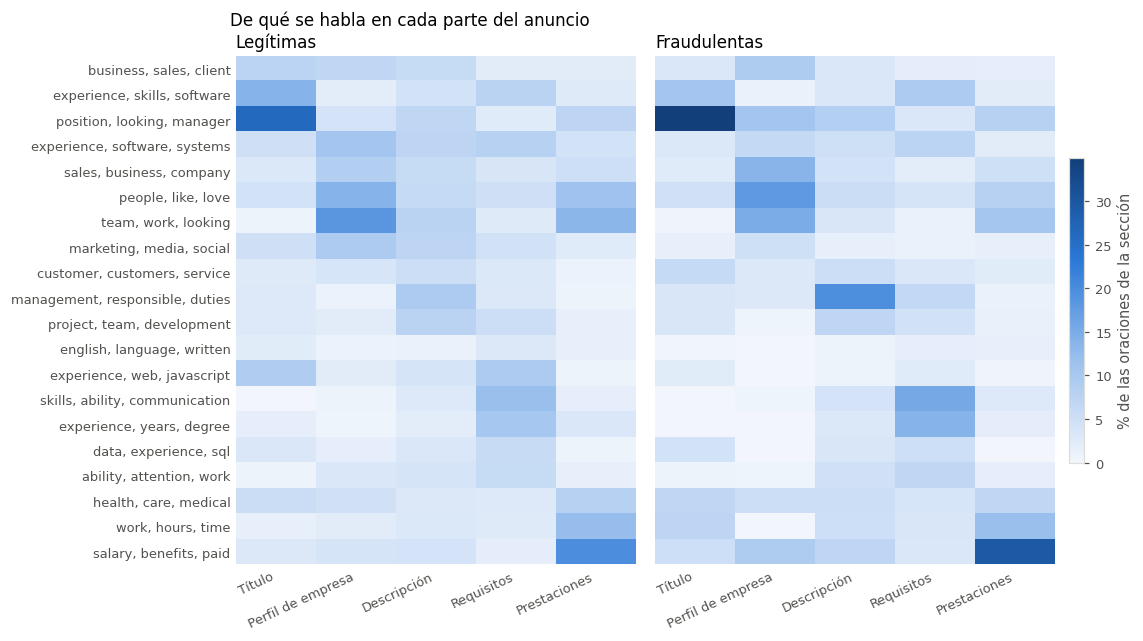

In [21]:
pct = {}
for cat in ["Legítima", "Fraudulenta"]:
    q = unicos_sec[unicos_sec["categoria"] == cat]
    pct[cat] = pd.crosstab(q["tema"], q["seccion"], normalize="columns")[SECCIONES] * 100
orden_t = pct["Legítima"].idxmax(axis=1).map(SECCIONES.index).sort_values(kind="stable").index
fig, ejes = plt.subplots(1, 2, figsize=(11.5, 6), sharey=True, gridspec_kw={"wspace": 0.05})
nombres = [NOMBRE_SEC[s] for s in SECCIONES]
vmax = max(p.to_numpy().max() for p in pct.values())
for ax, cat, titulo in zip(ejes, pct, ["Legítimas", "Fraudulentas"]):
    im = ax.imshow(pct[cat].loc[orden_t], cmap=SECUENCIAL, vmin=0, vmax=vmax, aspect="auto")
    ax.set_xticks(range(5), nombres, rotation=25, ha="right")
    ax.set_yticks(range(K_TEMAS), [ETIQUETA[t] for t in orden_t])
    ax.tick_params(length=0)
    for s in ax.spines.values():
        s.set_visible(False)
    ax.set_title(titulo, loc="left")
fig.colorbar(im, ax=ejes, shrink=0.6, pad=0.015, label="% de las oraciones de la sección")
fig.suptitle("De qué se habla en cada parte del anuncio", fontsize=11, x=0.12, ha="left", y=0.95)
plt.show()

El recorrido del anuncio se ve en las dos gráficas. En el título, lo más común es
`position, looking, manager`. El perfil usa el lenguaje de `team` y `people`, los requisitos se llenan
de `skills` y `experience`, y las prestaciones terminan en `salary, benefits, paid`. La secuencia es
casi la misma en las dos categorías.

Las diferencias confirman la sección 3.6. En las falsas, la descripción se carga hacia
`management, responsible, duties` (20 % de sus oraciones contra 9 %), y las prestaciones hablan más de
`salary, benefits, paid` (29 % contra 20 %). Lo más revelador está en el perfil de empresa: en las
falsas, esa sección habla más del pago (9 % contra 4 %) y del puesto (11 % contra 4 %). Es decir, aun
cuando traen un perfil de empresa, este dice menos sobre la empresa, lo que coincide con la
desconexión que vimos en 4.1.

### 4.3 Una misma palabra a lo largo del anuncio

Aquí entra BERT. Para cada palabra agrupo sus vectores con k-means y la silueta indica cuántos grupos
usar. Los nombres se asignan según las palabras que acompañan a cada grupo.

In [22]:
SENTIDOS = {
    "development": {"Software": r"software|web|agile|java|android|code|application",
                    "Negocio y carrera": r"business|career|professional|personal|sales|training",
                    "Elaboración de planes": r"plans?\b|strateg|implementation|procedures|policies|programs?\b"},
    "application": {"Postulación": r"resume|cv\b|submit|send|apply|letter|deadline|please|form\b",
                    "Software": r"web|mobile|software|developer|server|design|java|database"},
    "home": {"Estar o trabajar en casa": r"work|working|flexible|hours|office|stay",
             "Home como modificador": r"health|care|nursing|depot|improvement|services|products"},
    "service": {"Atención al cliente": r"customer|representative|client|skills|excellent",
                "Lo que ofrece la empresa": r"offer|best|provide|world|new|clients|quality",
                "Técnico y proveedor": r"provider|software|delivery|architecture|desk|solutions|cloud"},
}
K_SENTIDOS = {"development": 3, "application": 2, "home": 2, "service": 3}

silueta = {}
sentido = {}
for palabra, nombres in SENTIDOS.items():
    q, V = BERT[palabra]
    P = PCA(50, random_state=0).fit_transform(V - V.mean(0))
    silueta[palabra] = {k: silhouette_score(P, KMeans(k, n_init=5, random_state=0).fit_predict(P),
                                            sample_size=1500, random_state=0) for k in (2, 3, 4, 5)}
    km = KMeans(K_SENTIDOS[palabra], n_init=10, random_state=0).fit(P)
    # Nombro cada grupo según las palabras que lo acompañan.
    baja = q["oracion"].str.lower()
    afinidad = pd.DataFrame({n: pd.Series(baja.str.contains(r).to_numpy()).groupby(km.labels_).mean()
                             for n, r in nombres.items()})
    mapa, libres = {}, set(afinidad.index)
    for n in sorted(nombres, key=lambda n: -afinidad[n].max()):
        g = afinidad.loc[sorted(libres), n].idxmax()
        mapa[g] = n
        libres.remove(g)
    etiquetas = pd.Series(km.labels_).map(mapa).to_numpy()
    distancia = np.linalg.norm(P - km.cluster_centers_[km.labels_], axis=1)
    sentido[palabra] = {"etiqueta": etiquetas, "P": P, "distancia": distancia}
    print(f"\n{palabra}  (silueta: " + ", ".join(f"k={k} {v:.3f}" for k, v in silueta[palabra].items()) + ")")
    for n in nombres:
        k = etiquetas == n
        ej = q[k].assign(d=distancia[k]).sort_values("d")
        ej = ej[ej["oracion"].str.len().between(35, 100)]["oracion"].head(2).tolist()
        print(f"  {n:<26} {k.sum():>5}  {' | '.join(e[:62] for e in ej)}")


development  (silueta: k=2 0.145, k=3 0.153, k=4 0.110, k=5 0.108)
  Software                    1244  Experience with the full software development lifecycle. | Solid OIM Workflow development experience is mandatory
  Negocio y carrera            814  Makes independent business development calls. | Generates and manages outbound and inbound business developmen
  Elaboración de planes        421  Helping with the development of our partnership products and i | support the development of processes and operations alongside 



application  (silueta: k=2 0.263, k=3 0.204, k=4 0.197, k=5 0.137)
  Postulación                  570  We will notify people of interview times and dates via e-mail  | Prototyping showed our approach speeding up our client's appli
  Software                    1709  * Professional experience with n-tier application architecture | Be a key contributor in the front-end application development 

home  (silueta: k=2 0.159, k=3 0.158, k=4 0.155, k=5 0.126)
  Estar o trabajar en casa     569  The opportunity to manage your own time and work from home (Be | --Currently Fifty percent travel/50% work from home..
  Home como modificador        770  Great Home Health Opportunity for Physical Therapists! | At least 1 year of clinical experience in skilled home health



service  (silueta: k=2 0.138, k=3 0.144, k=4 0.126, k=5 0.111)
  Atención al cliente          995  - Customer service experience necessary. | Sales or customer service experience is helpful but not requir
  Lo que ofrece la empresa     668  Your energy and passion about the service will be a crucial ro | We are growing and we are looking for someone to own service f
  Técnico y proveedor          864  Develop complex service solutions and business models in coord | Works with customers to understand scope of field service proj


Los valores de silueta son bajos (0.14 a 0.26), lo que indica que los sentidos no son islas separadas:
hay zonas de transición. Hay que validar los grupos antes de creerles, y lo hago de dos maneras: con
una regla de palabras clave y leyendo una muestra al azar.

In [23]:
print("Acuerdo entre el grupo de BERT y una regla de palabras clave")
print("(solo oraciones donde aparece exactamente un conjunto de claves)\n")
CLAVES = {
    "application": {"Postulación": r"\b(resume|cv|cover letter|submit|deadline|apply)\b",
                    "Software": r"\b(web|mobile|software|developer|server|database|java)\b"},
    "home": {"Estar o trabajar en casa": r"\b(work|working) (from|at) home\b|\bstay.at.home\b",
             "Home como modificador": r"\b(home care|home health|nursing home|in.home|home depot|home improvement)\b"},
    "development": {"Software": r"\bsoftware development\b|\bweb development\b|\bapplication development\b",
                    "Negocio y carrera": r"\bbusiness development\b|\bcareer development\b|\bprofessional development\b"},
}
for palabra, reglas in CLAVES.items():
    q, _ = BERT[palabra]
    et = sentido[palabra]["etiqueta"]
    baja = q["oracion"].str.lower()
    marcas = pd.DataFrame({n: baja.str.contains(r, regex=True) for n, r in reglas.items()})
    k = (marcas.sum(axis=1) == 1).to_numpy()
    regla = marcas[k].idxmax(axis=1).to_numpy()
    print(f"{palabra:<12} {k.sum():>4} oraciones, acuerdo {(regla == et[k]).mean():.1%}")

print("\nMuestra al azar de un grupo, sin filtrar por palabras clave:\n")
for palabra, grupo in [("application", "Postulación"), ("home", "Estar o trabajar en casa")]:
    q, _ = BERT[palabra]
    print(f"{palabra} / {grupo}")
    for t in q[sentido[palabra]["etiqueta"] == grupo].sample(22, random_state=7)["oracion"]:
        i = t.lower().find(palabra)
        print("   " + t[max(0, i - 42):i + 42].replace("\n", " "))
    print()

Acuerdo entre el grupo de BERT y una regla de palabras clave
(solo oraciones donde aparece exactamente un conjunto de claves)

application   904 oraciones, acuerdo 97.6%
home          480 oraciones, acuerdo 98.8%
development   659 oraciones, acuerdo 96.1%

Muestra al azar de un grupo, sin filtrar por palabras clave:

application / Postulación
   Please attach this to your initial application.
   career progression and more, send in your application and join us on the journey.
   - Assist potential clients with the application for government benefits direct
   any where you have a direct impact on the application is here - are you up for the c
   Once we review your application we will provide further detail
   king forward to receiving your convincing application either in German or in English
   l social media account would benefit your application.
   mediate consideration, please complete an application and attach your resume at .
   answering the following questions on this applica

El acuerdo con las palabras clave pasa de 95 %, pero esa cifra es optimista, porque solo cubre los
casos obvios. La lectura de la muestra es más exigente:

- **`application` / Postulación:** de las 22 oraciones, unas 14 son postulaciones a un empleo, 3 son
  otro tipo de solicitud (un préstamo o un trámite de gobierno) y 5 no pertenecen al grupo, como
  `Single Page Application`. Eso también explica el ejemplo equivocado de la celda anterior
  (`Prototyping showed...`). El grupo capta bien la idea de "solicitud", pero con ruido.
- **`home`:** unas 12 oraciones hablan de trabajar desde casa, 6 de la casa en sentido literal y 4 son
  expresiones (`feel right at home`). Por eso el grupo se llama "Estar o trabajar en casa". Lo que BERT
  separa en realidad es `home` como lugar frente a `home` como modificador (`home care`, `home improvement`).

Los conteos son una revisión manual de una muestra pequeña y dan una idea del orden de magnitud, no
una medida exacta. Los resultados siguientes hay que leerlos como aproximados.

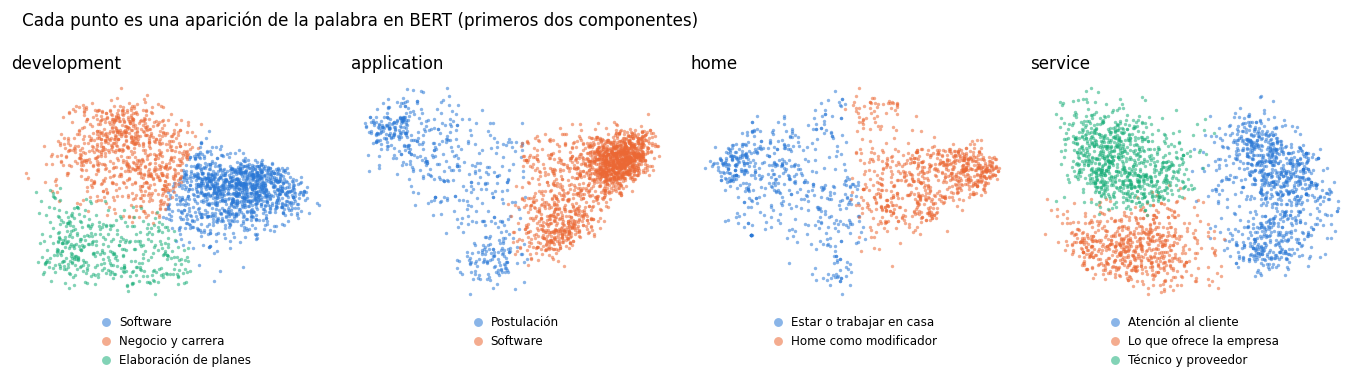

In [24]:
fig, ejes = plt.subplots(1, 4, figsize=(12.5, 3.5))
for ax, (palabra, nombres) in zip(ejes, SENTIDOS.items()):
    et, P = sentido[palabra]["etiqueta"], sentido[palabra]["P"]
    for n, color in zip(nombres, SERIES):
        k = et == n
        ax.scatter(P[k, 0], P[k, 1], s=5, color=color, alpha=0.55, linewidths=0, label=n)
    ax.set_title(palabra, loc="left")
    ax.set_xticks([])
    ax.set_yticks([])
    for s in ax.spines.values():
        s.set_visible(False)
    ax.legend(loc="upper center", bbox_to_anchor=(0.5, 0.0), markerscale=2.6, handletextpad=0.1, fontsize=7.8)
fig.suptitle("Cada punto es una aparición de la palabra en BERT (primeros dos componentes)",
             fontsize=11, x=0.02, ha="left")
fig.tight_layout()
plt.show()

Cada punto es una aparición. Si BERT no distinguiera sentidos, cada palabra sería una sola nube. En
cambio se ven regiones separadas, con zonas de transición entre ellas. Esto muestra lo que no puede
hacer Word2Vec, que a cada palabra le da un solo punto en vez de una nube.

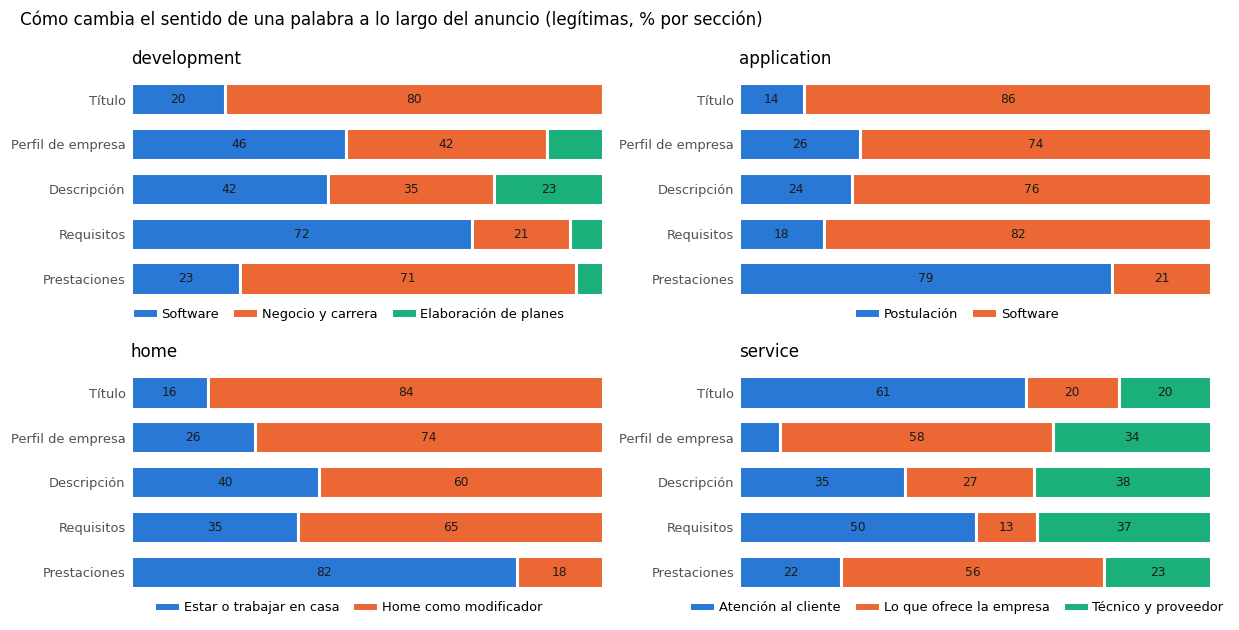

In [25]:
fig, ejes = plt.subplots(2, 2, figsize=(11.5, 5.8))
for ax, (palabra, nombres) in zip(ejes.ravel(), SENTIDOS.items()):
    q, _ = BERT[palabra]
    et = sentido[palabra]["etiqueta"]
    k = (q["categoria"] == "Legítima").to_numpy()
    t = pd.crosstab(q["seccion"][k], et[k], normalize="index").reindex(SECCIONES).fillna(0)[list(nombres)] * 100
    y = np.arange(5)[::-1]
    izquierda = np.zeros(5)
    for n, color in zip(nombres, SERIES):
        ax.barh(y, t[n], left=izquierda, color=color, height=0.72, edgecolor="white", linewidth=2, label=n)
        for yi, l, v in zip(y, izquierda, t[n]):
            if v >= 12:
                ax.text(l + v / 2, yi, f"{v:.0f}", ha="center", va="center", fontsize=8, color="#1b1a18")
        izquierda += t[n].to_numpy()
    ax.set_yticks(y, [NOMBRE_SEC[s] for s in SECCIONES])
    ax.set_xlim(0, 100)
    ax.set_xticks([])
    ax.tick_params(length=0)
    for s in ax.spines.values():
        s.set_visible(False)
    ax.set_title(palabra, loc="left")
    ax.legend(loc="upper center", bbox_to_anchor=(0.46, 0.04), ncol=3, handletextpad=0.3, columnspacing=1)
fig.suptitle("Cómo cambia el sentido de una palabra a lo largo del anuncio (legítimas, % por sección)",
             fontsize=11, x=0.02, ha="left")
fig.tight_layout()
plt.show()

Esta es la gráfica más clara de que el significado depende del contexto:

- **`application`:** es software en casi todo el anuncio (entre 74 % y 86 %), pero en prestaciones
  pasa a significar postulación en el 79 % de los casos.
- **`development`:** en requisitos es software (72 %), y en título y prestaciones es negocio y carrera
  (80 % y 71 %), como en `business development` y `career development`.
- **`home`:** pasa de 16 % en títulos a 82 % en prestaciones, donde es trabajar desde casa como beneficio.
- **`service`:** en requisitos es atención al cliente (50 %), y en perfil y prestaciones es lo que la
  empresa ofrece (58 % y 56 %).

Para medir esto en las 12 palabras sin depender de los grupos, calculo qué porcentaje de la varianza
de los vectores de BERT se explica por la sección, restando lo que daría el azar. La autosimilitud es
el coseno promedio entre dos apariciones de la misma palabra: mientras más baja, más cambia su sentido.

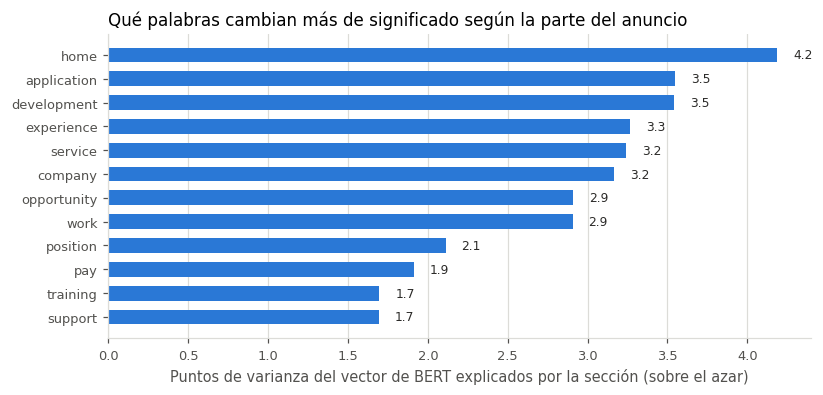

    Palabra  % varianza por sección  Autosimilitud
    support                   1.691          0.620
   training                   1.696          0.716
        pay                   1.913          0.610
   position                   2.111          0.665
       work                   2.906          0.612
opportunity                   2.910          0.682
    company                   3.166          0.701
    service                   3.239          0.640
 experience                   3.263          0.680
development                   3.540          0.652
application                   3.548          0.657
       home                   4.187          0.589


In [26]:
def varianza_explicada(V, grupos):
    centro = V.mean(0)
    total = ((V - centro) ** 2).sum()
    entre = sum((grupos == g).sum() * ((V[grupos == g].mean(0) - centro) ** 2).sum() for g in np.unique(grupos))
    return entre / total

filas = []
for palabra in PALABRAS:
    q, V = BERT[palabra]
    k = (q["categoria"] == "Legítima").to_numpy()
    sec = q["seccion"].to_numpy()[k]
    Vk = V[k]
    obs = varianza_explicada(Vk, sec)
    nula = np.mean([varianza_explicada(Vk, rng.permutation(sec)) for _ in range(50)])
    a, b = rng.integers(0, len(V), (2, 3000))
    k2 = a != b
    Vn = unitario(V)
    filas.append((palabra, 100 * (obs - nula), (Vn[a[k2]] * Vn[b[k2]]).sum(1).mean()))
contexto = pd.DataFrame(filas, columns=["Palabra", "% varianza por sección", "Autosimilitud"]).sort_values("% varianza por sección")

fig, ax = plt.subplots(figsize=(7.6, 3.7))
y = np.arange(len(contexto))
ax.barh(y, contexto["% varianza por sección"], color=AZUL, height=0.62)
ax.set_yticks(y, contexto["Palabra"])
for yi, v in zip(y, contexto["% varianza por sección"]):
    ax.text(v + 0.1, yi, f"{v:.1f}", va="center", fontsize=8, color="#2b2a28")
ax.set_xlabel("Puntos de varianza del vector de BERT explicados por la sección (sobre el azar)")
ax.set_title("Qué palabras cambian más de significado según la parte del anuncio", loc="left")
estilizar(ax, "x")
fig.tight_layout()
plt.show()
print(contexto.round(3).to_string(index=False))

`home` es la que más cambia y también la de menor autosimilitud (0.59). Le siguen `application` y
`development`, que eran las que yo esperaba. En cambio `training`, `support` y `pay` dependen poco de la
sección. El efecto parece pequeño (entre 1.7 y 4.2 puntos) porque la mayor parte de la varianza de BERT
viene del resto de la oración, y la sección es apenas un dato más.

### 4.4 ¿Las ofertas falsas usan las palabras con otro sentido?

Comparo los sentidos entre categorías dentro de cada combinación de industria y sección.

In [27]:
filas = []
OBJETIVO = {"application": "Postulación", "home": "Estar o trabajar en casa", "development": "Software",
            "service": "Atención al cliente"}
for palabra, objetivo in OBJETIVO.items():
    q, _ = BERT[palabra]
    y = sentido[palabra]["etiqueta"] == objetivo
    f = (q["categoria"] == "Fraudulenta").to_numpy()
    estrato = (q["industria"] + "|" + q["seccion"]).to_numpy()
    razon, p = cmh(f, y, estrato)
    filas.append((palabra, objetivo, int(f.sum()), y[f].mean(), y[~f].mean(), razon, p))
print(pd.DataFrame(filas, columns=["Palabra", "Sentido", "n fraude", "Fraude", "Legítima",
                                   "OR ajustada", "p"]).round(3).to_string(index=False))

    Palabra                  Sentido  n fraude  Fraude  Legítima  OR ajustada     p
application              Postulación        80   0.550     0.239        2.792 0.000
       home Estar o trabajar en casa       112   0.589     0.410        2.350 0.000
development                 Software       279   0.362     0.520        0.821 0.296
    service      Atención al cliente       329   0.535     0.373        2.031 0.000


Aquí está uno de los resultados más interesantes. En las ofertas falsas, `application` se usa más como
postulación (55 % contra 24 %), `home` como estar o trabajar en casa (59 % contra 41 %) y `service` como
atención al cliente (54 % contra 37 %), y las tres se sostienen al controlar industria y sección.

`development` es el contraejemplo útil: en crudo parece menos ligada a software en las falsas (36 %
contra 52 %), pero con el ajuste la diferencia deja de ser significativa (p = 0.30). Era solo el sector.

Hay que recordar dos cosas. Algunas oraciones vienen del mismo anuncio, así que no son del todo
independientes y los valores p son optimistas. Y solo hay 80 oraciones falsas con `application`. Aun
así, el resultado coincide con la sección 3.6: la oferta falsa habla del acto de postularse y de la
comodidad del puesto.

### 4.5 Coherencia entre oraciones vecinas

Por último mido cuánto cambia el tema de una oración a la siguiente, con el coseno entre oraciones
consecutivas de una misma sección. Un valor alto significa que el texto se queda en el mismo tema.

In [28]:
o = oraciones[["doc", "seccion", "uid"]]
misma = (o["doc"].to_numpy()[1:] == o["doc"].to_numpy()[:-1]) & (o["seccion"].to_numpy()[1:] == o["seccion"].to_numpy()[:-1])
i = np.where(misma)[0]
uid = o["uid"].to_numpy()
pares_adj = pd.DataFrame({"doc": o["doc"].to_numpy()[i], "seccion": o["seccion"].to_numpy()[i],
                          "c": (E[uid[i]] * E[uid[i + 1]]).sum(1)})
por_sec = pares_adj.groupby(["seccion", "doc"])["c"].agg(["mean", "size"]).reset_index()
por_sec = por_sec[(por_sec["size"] >= 2) & por_sec["doc"].isin(representantes)]
por_sec["fraude"] = fraude[por_sec["doc"]]
por_sec["industria"] = docs["industria"].to_numpy()[por_sec["doc"]]

filas = []
for s in SECCIONES[1:]:
    g = por_sec[por_sec["seccion"] == s]
    f, l = g[g["fraude"]]["mean"], g[~g["fraude"]]["mean"]
    signos = []
    for industria in top_fraude.head(4).index:
        h = g[g["industria"] == industria]
        a, b = h[h["fraude"]]["mean"], h[~h["fraude"]]["mean"]
        signos.append("+" if len(a) >= 5 and a.median() > b.median() else "-" if len(a) >= 5 else "·")
    filas.append((NOMBRE_SEC[s], len(f), f.median(), l.median(), mannwhitneyu(f, l).pvalue, " ".join(signos)))
print(pd.DataFrame(filas, columns=["Sección", "n fraude", "Fraude", "Legítima", "p",
                                   "Signo en 4 industrias"]).round(4).to_string(index=False))

          Sección  n fraude  Fraude  Legítima      p Signo en 4 industrias
Perfil de empresa       142  0.3371    0.3558 0.0027               - · · -
      Descripción       454  0.3163    0.3255 0.0427               - - - -
       Requisitos       319  0.3154    0.2892 0.0000               + - · +
     Prestaciones       113  0.3092    0.2433 0.0000               + + · ·


En prestaciones y requisitos, las ofertas falsas tienen oraciones vecinas más parecidas entre sí (0.31
contra 0.24 en prestaciones), y en perfil y descripción ocurre al revés, con diferencias pequeñas. La
última columna da el signo dentro de las cuatro industrias con más fraude (`+` falsas mayor, `-` menor,
`·` menos de 5 ofertas) y muestra que **este resultado es débil**. Solo la descripción tiene el mismo
signo en las cuatro, pero esa diferencia es mínima (0.316 contra 0.326, p = 0.04), y en prestaciones
apenas hay dos industrias con datos suficientes. No lo tomaría como rasgo del fraude.

## 5. Visualización e interpretación

Cada sección anterior ya incluye sus gráficas con su interpretación. Las principales son la red
semántica (3.1), el mapa de roles (3.2), el mapa de industrias (3.3), la nube de sentidos de BERT (4.3)
y la evolución de sentidos por sección (4.3). Falta la vista general del corpus: un mapa de los
documentos. t-SNE reduce las 384 dimensiones a 2 tratando de conservar quién es vecino de quién. Uso
una oferta por campaña, todas las fraudulentas y 3,500 legítimas al azar.

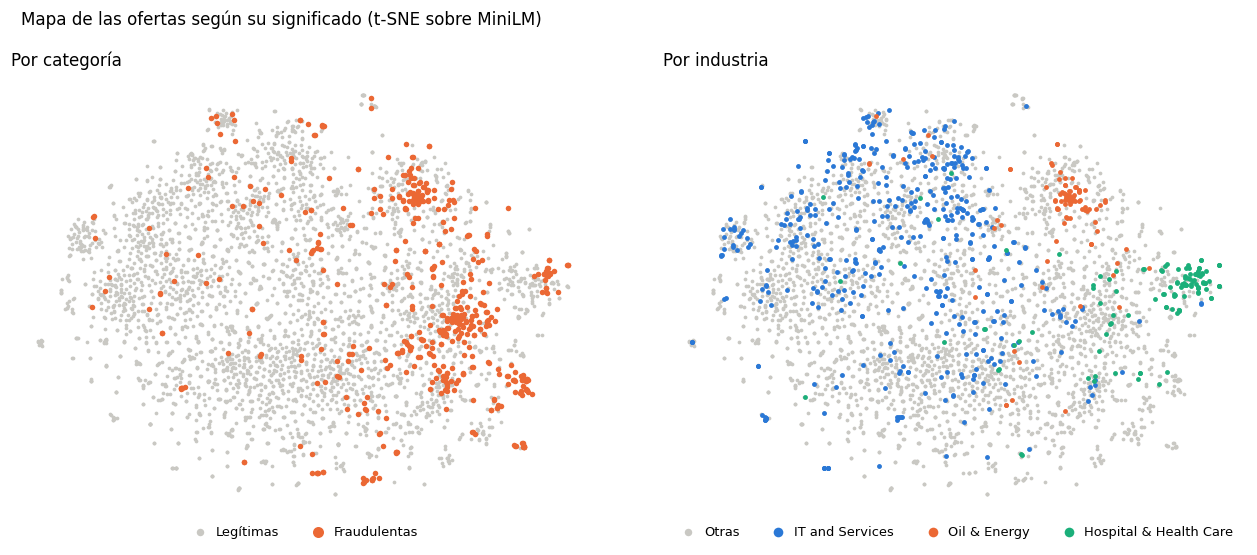

In [29]:
legit = rng.choice(np.where(rep_mask & ~fraude)[0], 3500, replace=False)
sel = np.concatenate([legit, np.where(rep_mask & fraude)[0]])
Y = TSNE(n_components=2, perplexity=40, init="pca", random_state=SEMILLA, max_iter=750).fit_transform(D[sel])
f = fraude[sel]
ind_sel = docs["industria"].to_numpy()[sel]

fig, ejes = plt.subplots(1, 2, figsize=(12, 5.1))
ax = ejes[0]
ax.scatter(*Y[~f].T, s=6, color=TENUE, linewidths=0, label="Legítimas")
ax.scatter(*Y[f].T, s=13, color=NARANJA, linewidths=0, label="Fraudulentas")
ax.set_title("Por categoría", loc="left")
ax = ejes[1]
ax.scatter(*Y.T, s=6, color=TENUE, linewidths=0, label="Otras")
for nombre, color in [("Information Technology and Services", AZUL), ("Oil & Energy", NARANJA),
                      ("Hospital & Health Care", VERDE)]:
    k = ind_sel == nombre
    ax.scatter(*Y[k].T, s=10, color=color, linewidths=0, label=corto(nombre))
ax.set_title("Por industria", loc="left")
for ax in ejes:
    ax.set_xticks([])
    ax.set_yticks([])
    for s in ax.spines.values():
        s.set_visible(False)
    ax.legend(loc="upper center", bbox_to_anchor=(0.5, 0.0), ncol=4, markerscale=2, handletextpad=0.2)
fig.suptitle("Mapa de las ofertas según su significado (t-SNE sobre MiniLM)", fontsize=11, x=0.02, ha="left")
fig.tight_layout()
plt.show()

El mapa de la derecha muestra que el significado se organiza primero por sector: las ofertas de
tecnología ocupan una zona amplia, y salud y petróleo forman núcleos compactos. El de la izquierda
muestra que las ofertas falsas no forman una isla: están repartidas por casi todo el mapa, aunque se
concentran en algunos núcleos compactos, y uno de ellos coincide con el de petróleo.

Coincide con todo lo anterior: el fraude no es un tema, sino que se mete dentro de los temas que ya
existen, aunque en algunos sectores se concentra. Hay que leer este mapa con cuidado: t-SNE conserva
bien a los vecinos cercanos, pero las distancias largas y el tamaño de las regiones no significan nada.

## 6. Conclusiones y relación con el proyecto final

**¿Qué conceptos aparecen relacionados?** Sin supervisión, el vocabulario se organiza en comunidades
reconocibles: personas, tecnología, empresa, marketing, clientes, requisitos y condiciones del puesto.
Las industrias se dividen en un bloque digital y uno de operaciones físicas y servicios.

**¿Qué palabras son cercanas?** Las que se usan igual en este corpus, y eso depende del corpus:
`visa` significa permiso de trabajo y `greece` se acerca a empresas griegas.

**¿Hay diferencia entre similitud léxica y semántica?** Sí. `cv` y `resume` no comparten letras, y dos
frases con el mismo molde pueden hablar de cosas sin relación (TF-IDF de 0.81, coseno de 0.08). Las dos
medidas se correlacionan entre anuncios (0.72), pero no se sustituyen. Además, los embeddings miden
relación y no sinonimia: `senior` y `junior` quedan cerca.

**¿Cambia el significado con el contexto?** Sí, y de forma medible. `application` significa software
en casi todo el anuncio y postulación en prestaciones. Un vector por palabra no puede ver esto.

**Lo que esta práctica aporta sobre el fraude:**

1. **No hay vocabulario de estafa.** Los conceptos típicos de una estafa casi no distinguen (AUC entre
   0.40 y 0.60) y cambian de sentido según la industria. `Trabajo desde casa` da 0.48.
2. **El fraude imita.** Una oferta falsa se parece a las legítimas de su sector y sigue la misma
   estructura de un anuncio real (correlación de 0.85 entre secciones).
3. **Lo que lo delata es el énfasis.** Con el ajuste por industria y longitud, las ofertas falsas
   hablan más de pago y horarios y menos de tecnología, equipo y conocimientos concretos. Las palabras
   ambiguas también se inclinan hacia postularse y hacia la comodidad del puesto.
4. **El parecido entre ofertas falsas depende del sector.** Se sostiene en salud y contabilidad, baja en
   petróleo y era pura plantilla en marketing.

Esto se integra bien con las prácticas anteriores. El perfil lingüístico de una oferta falsa ya era el
de un texto más corto (P1), que omite a la empresa (P1), que le habla al candidato con `your` (P3) y
que usa oraciones más simples (P4). Esta práctica agrega que su contenido también es menos específico:
promete condiciones y da pocos detalles verificables. Es lo mismo que encontré en la Práctica 1 desde
otro ángulo: **el fraude se delata más por lo que omite que por lo que dice**.

Tres lecciones de método sirven para el análisis final, porque aquí cambiaron las conclusiones:
controlar plantillas (la señal de marketing desapareció), controlar la longitud (el panorama de temas
cambió por completo) y leer ejemplos en vez de confiar en una sola métrica (los grupos de BERT tenían
más ruido del que indicaba el 95 % de acuerdo).

**Limitaciones.** Hay solo 680 ofertas falsas y 501 grupos, y por industria son pocas decenas. El umbral
de campañas no detecta plantillas reescritas. El vector de documento promedia y pierde detalle. Los
grupos de sentidos son aproximados y solo cubren 12 palabras. Además, los resultados describen las
ofertas de EMSCAD, que se recolectaron hace años y con el sesgo geográfico ya visto, por lo que no
necesariamente aplican a las estafas actuales.

Por último guardo los artefactos, que quedan disponibles en `corpus_procesado/embeddings/`.

In [30]:
pd.DataFrame({"doc_id": docs["doc_id"], "campana": docs["campana"]}).to_csv(EMB / "campanas.csv.gz", index=False)
pd.DataFrame({"oracion": unicas, "tema": tema_u}).to_parquet(EMB / "oraciones_temas.parquet")
for archivo in sorted(EMB.iterdir()):
    print(f"{archivo.name:<34} {archivo.stat().st_size / 1024**2:7.1f} MB")

bert_contextual.npz                   37.5 MB
bert_contextual.parquet                2.0 MB
campanas.csv.gz                        0.1 MB
fasttext.kv                            8.4 MB
fasttext.kv.vectors_ngrams.npy       152.6 MB
oraciones_temas.parquet               12.2 MB
sbert_documentos.npy                  10.4 MB
sbert_oraciones.npy                  177.8 MB
word2vec.kv                            8.4 MB
